# calc_03a. ERA5: model evaluation (calculations)

Two questions, asked of ERA5 and the LESFMIP ensembles over the years they share (1979–2013):

1. **Is each model consistent with ERA5?** Could ERA5 be one more member of a model's historical ensemble? (Part 1, this notebook)
2. **Is the observed change detectable, and which forcings is it consistent with?** (Part 2, notebook calc_03b)

This notebook works out part 1 and saves it in `RESULTS_DIR` (`results/tas/sample` or `results/tas/full` under `SCRATCH_DIR`); notebook plot_01 opens the results of both parts and draws the figures.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from extant import datatree, era5_evaluation as ev, observed_change as oc, preprocessing as pp
from extant.config import MAIN_EXPERIMENTS, SATELLITE_YEAR_RANGE, VARIABLES
from extant.datatree import skip_empty, tree_to_dataset
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from plotting_modules.constants import FORCING_COLORS, SEASONS

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

The experiments (`MAIN_EXPERIMENTS`) and the years ERA5 and LESFMIP share (`SATELLITE_YEAR_RANGE`) are in `extant/config.py`, and the order of the seasons (`SEASONS`) in `plotting_modules/constants.py`, the same for every notebook. Only this notebook's own choices are here.

In [3]:
#(t): The variable: its name and its units once notebook calc_01 has converted it (VARIABLE.name, VARIABLE.units)
VARIABLE = VARIABLES['tas']

In [4]:
#(t): The grid point of the tests at one point (the 2.5° cell nearest config.POINT, on the Antarctic plateau)
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)

#(t): The model of the one-model quick looks
EXAMPLE_MODEL = 'CanESM5'

In [5]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means, /<model>/<experiment>, on member × year × season × lat × lon), `era5_seasonal_da` (ERA5 on year × season × lat × lon, on the same grid), all in °C, and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around the point in `tests/data` (two models), put through notebook calc_01's pre-processing.

In [6]:
#(t): The sample's files, in this repository: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
SAMPLE_DIR = Path('../tests/data')
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [7]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [8]:
#(t): Each file of the experiments analysed opened, as a DataTree /<model>/<experiment>
lesfmip_monthly_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                              for path, (model, experiment) in zip(sample_files, sample_names)
                                              if experiment in MAIN_EXPERIMENTS})

In [9]:
#(t): Seasonal means in °C, through notebook calc_01's pre-processing (pp.seasonal_tree: to °C, cut at 2014-12, complete
#(t): seasons in whole years)
lesfmip_season_tree = pp.seasonal_tree(lesfmip_monthly_tree, VARIABLE.name).compute()
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 3, lon: 3, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 1MB -32.91 ... -48.19
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 3, lon: 3, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 1kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 708kB -33.69 ... -51.24
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 3, lon: 3, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 1MB -32.82 ... -50.6
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 3, lon: 3, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 360B 'r10i1p1f1' 'r1i1p1f1' ... 'r8i1p1f1' 'r9i1p1f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 236kB -33.95 ... -51.24
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 3, lon: 3, year: 164, season: 4)
│           Coordinates:
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 24B 117.5 120.0 122.5
│             * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│             * lat      (lat) float64 24B -85.0 -82.5 -80.0
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 2MB -33.68 ... -46.4
└── Group: /HadGEM3-GC31-LL
    ├── Group: /HadGEM3-GC31-LL/hist-GHG
    │       Dimensions:  (member: 55, lat: 3, lon: 3, year: 164, season: 4)
    │       Coordinates:
    │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
    │         * member   (member) <U9 2kB 'r11i1p1f3' 'r12i1p1f3' ... 'r5i1p1f3' 'r60i1p1f3'
    │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
    │         * lon      (lon) float64 24B 117.5 120.0 122.5
    │       Data variables:
    │           tas      (member, lat, lon, year, season) float32 1MB -30.42 ... -43.42
    ├── Group: /HadGEM3-GC31-LL/hist-aer
    │       Dimensions:  (member: 55, lat: 3, lon: 3, year: 164, season: 4)
    │       Coordinates:
    │         * year     (year) int64 1k

In [10]:
#(t): ERA5's sample file: monthly tas in K from 1979, on (time, lat, lon)
era5_sample_path = SAMPLE_DIR / 'era5_sample.nc'
era5_monthly_da = xr.open_dataarray(era5_sample_path).load()
era5_sample_path

PosixPath('../tests/data/era5_sample.nc')

In [11]:
#(t): Its seasonal means in °C, on the models' grid (pp.seasonal_era5, as in notebook calc_01)
era5_seasonal_da = pp.seasonal_era5(era5_monthly_da, VARIABLE.name, like=lesfmip_season_tree)
era5_seasonal_da

<xarray.DataArray 'tas' (lat: 3, lon: 3, year: 45, season: 4)> Size: 6kB
-33.54 -55.68 -52.21 -46.23 -34.05 -55.91 ... -46.72 -34.05 -54.03 -51.15 -46.15
Coordinates:
  * year     (year) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
  * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 24B -85.0 -82.5 -80.0
  * lon      (lon) float64 24B 117.5 120.0 122.5

In [12]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`. Opening is lazy.

In [13]:
#(t): The two stores notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
era5_path = SCRATCH_DIR / 'seasonal' / f'era5_{VARIABLE.name}.zarr'
seasonal_path, era5_path

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr'),
 PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/era5_tas.zarr'))

In [14]:
#(t): Every model and experiment notebook calc_01 saved
lesfmip_saved_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [15]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_saved_tree.filter(lambda node: node.name in MAIN_EXPERIMENTS)
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0

In [16]:
#(t): ERA5's seasonal means
era5_seasonal_da = xr.open_zarr(era5_path)[VARIABLE.name].load()
era5_seasonal_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, year: 45, season: 4)> Size: 2MB
-29.25 -47.32 -43.3 -40.75 -29.31 -46.72 ... 15.65 13.54 18.27 11.52 15.93 13.68
Coordinates:
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * year     (year) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023

In [17]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

### What was opened

Whichever section ran. An empty square is a model and experiment that was never opened.

In [18]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                              for node in lesfmip_season_tree.leaves}).unstack()
member_counts_df = member_counts_df.reindex(columns=MAIN_EXPERIMENTS)

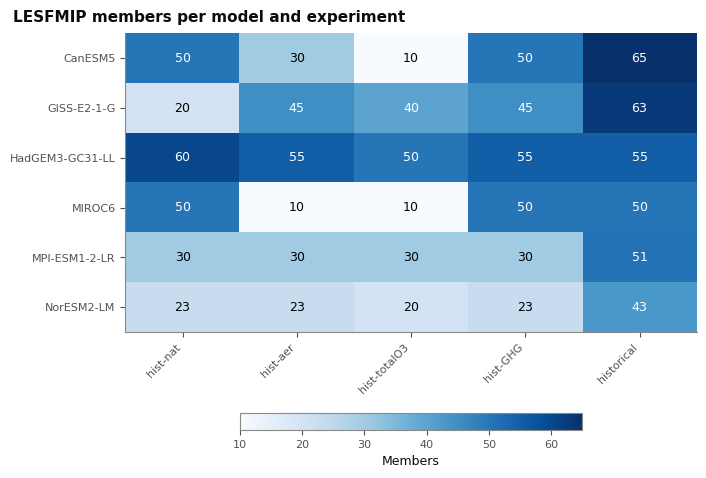

In [19]:
#(t): The members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

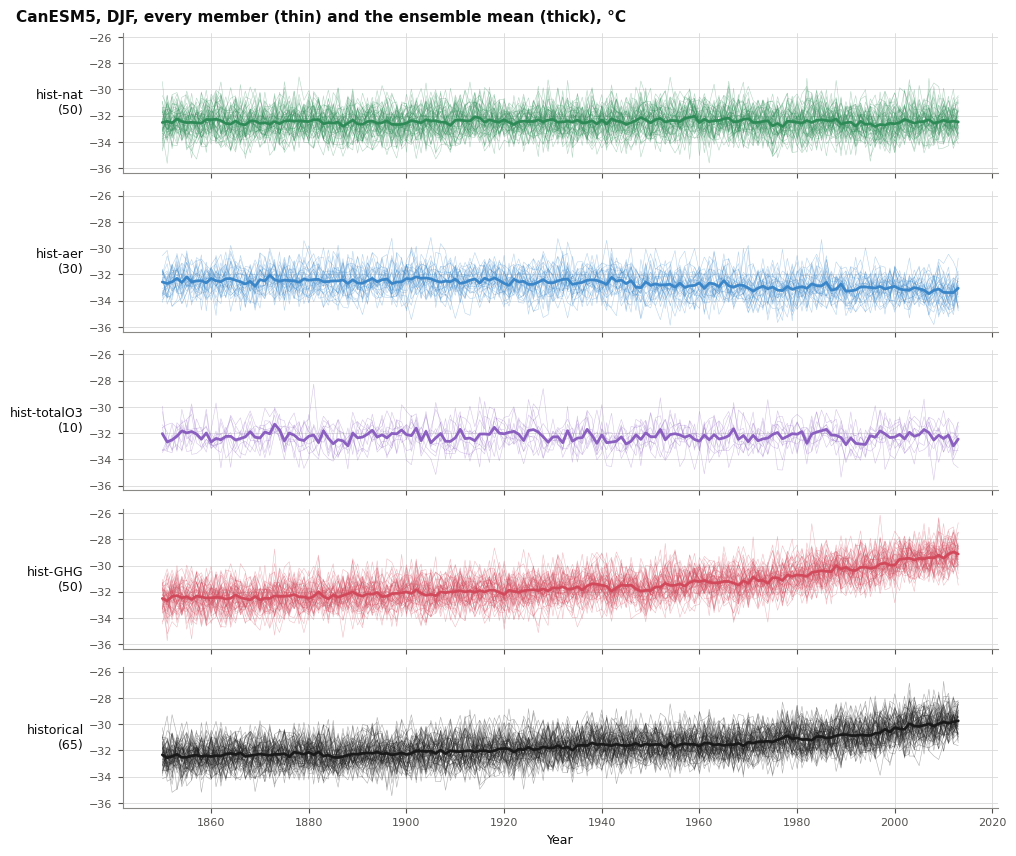

In [20]:
#(t): Each experiment's members at the point (one model, DJF): every member (thin) and the ensemble mean (thick), one
#(t): row each, the number of members beside it
model_point_tree = lesfmip_season_tree[EXAMPLE_MODEL].sel(**SAMPLE_LAT_LON).load()
point_experiments = [e for e in MAIN_EXPERIMENTS if e in model_point_tree.children]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(point_experiments), n_cols=1, n_legends=0,
                                                  panel_width=8.5, panel_height=1.0, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(point_experiments), 1).subplots(sharex=True, sharey=True, squeeze=False)
for ax, experiment in zip(axes[:, 0], point_experiments):
    experiment_members_da = model_point_tree[experiment][VARIABLE.name].sel(season='DJF')
    charts.plot_lines(experiment_members_da, 'year', ax=ax, color=FORCING_COLORS[experiment], linewidth=0.4, alpha=0.35)
    charts.plot_lines(experiment_members_da.mean('member'), 'year', ax=ax, color=FORCING_COLORS[experiment],
                      linewidth=2)
    ax.set_ylabel(f"{experiment}\n({experiment_members_da.sizes['member']})", rotation=0, ha='right', va='center')
axes[-1, 0].set_xlabel('Year')
fig.suptitle(f'{EXAMPLE_MODEL}, DJF, every member (thin) and the ensemble mean (thick), {VARIABLE.units}', x=0.01,
             ha='left');

## Climatologies

Every season: the 1979–2013 average (the climatology) and the year-to-year spread of ERA5 and of each model's historical ensemble, how they differ, the area mean through time, and one model's experiments. The models' climatology minus ERA5's is the mean-state bias, which only the tests of raw values see; every other test removes it.

### ERA5

In [21]:
#(t): ERA5's climatology: its mean over SATELLITE_YEAR_RANGE in each season, on (season, lat, lon)
era5_climatology_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS).mean('year')
era5_climatology_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4)> Size: 46kB
-29.67 -44.06 -47.49 -40.89 -29.48 -43.8 ... 9.007 11.59 17.23 15.03 10.95 12.92
Coordinates:
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5

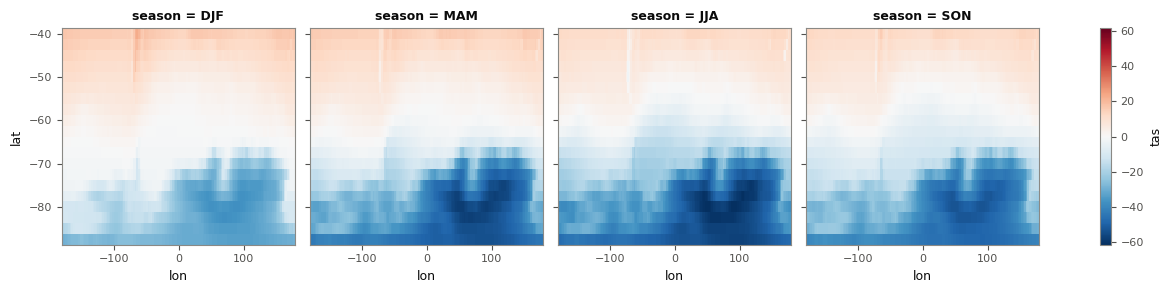

In [22]:
era5_climatology_da.plot(x='lon', y='lat', col='season', cmap='RdBu_r');

In [23]:
#(t): ERA5's year-to-year spread: the standard deviation of its seasonal means over SATELLITE_YEAR_RANGE
era5_std_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS).std('year')

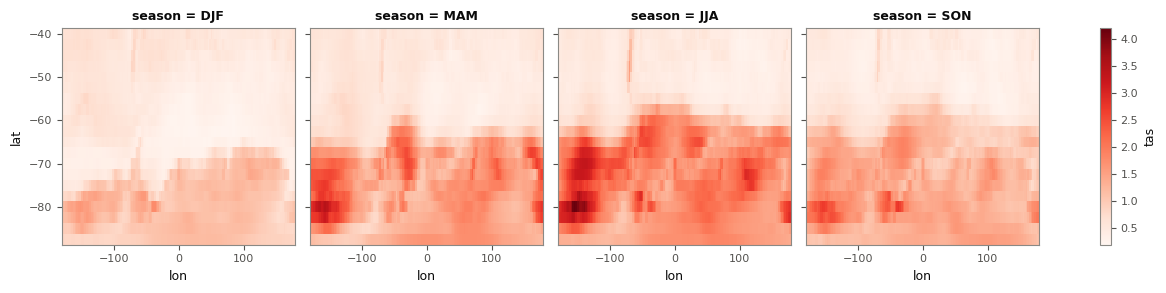

In [24]:
era5_std_da.plot(x='lon', y='lat', col='season', cmap='Reds');

In [25]:
#(t): ERA5 south of 60°S
era5_south_da = era5_seasonal_da.sel(season=SEASONS, lat=slice(None, -60))

In [26]:
#(t): its area mean in every year (cos-latitude weighted)
era5_area_weights_da = np.cos(np.deg2rad(era5_south_da.lat))
era5_area_mean_da = era5_south_da.weighted(era5_area_weights_da).mean(['lat', 'lon'])

### Historical ensembles

In [27]:
#(t): Each model's historical ensemble
historical_tree = lesfmip_season_tree.match('*/historical')

In [28]:
#(t): over SATELLITE_YEAR_RANGE, in the seasons' order
historical_eval_tree = historical_tree.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS)

In [29]:
#(t): Each model's climatology: the mean over the years and the members
historical_climatology_tree = historical_eval_tree.mean(['year', 'member'])

In [30]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_climatology_ds = datatree.tree_to_dataset(historical_climatology_tree, dims=['model', 'experiment']).load()
historical_climatology_da = historical_climatology_ds[VARIABLE.name].sel(experiment='historical', drop=True)
historical_climatology_da

CPU times: user 3.36 s, sys: 5.38 s, total: 8.74 s
Wall time: 3.42 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6)> Size: 276kB
-25.62 -99.11 -27.64 -19.52 -28.13 -28.86 ... -68.89 13.03 14.82 11.93 14.17
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'

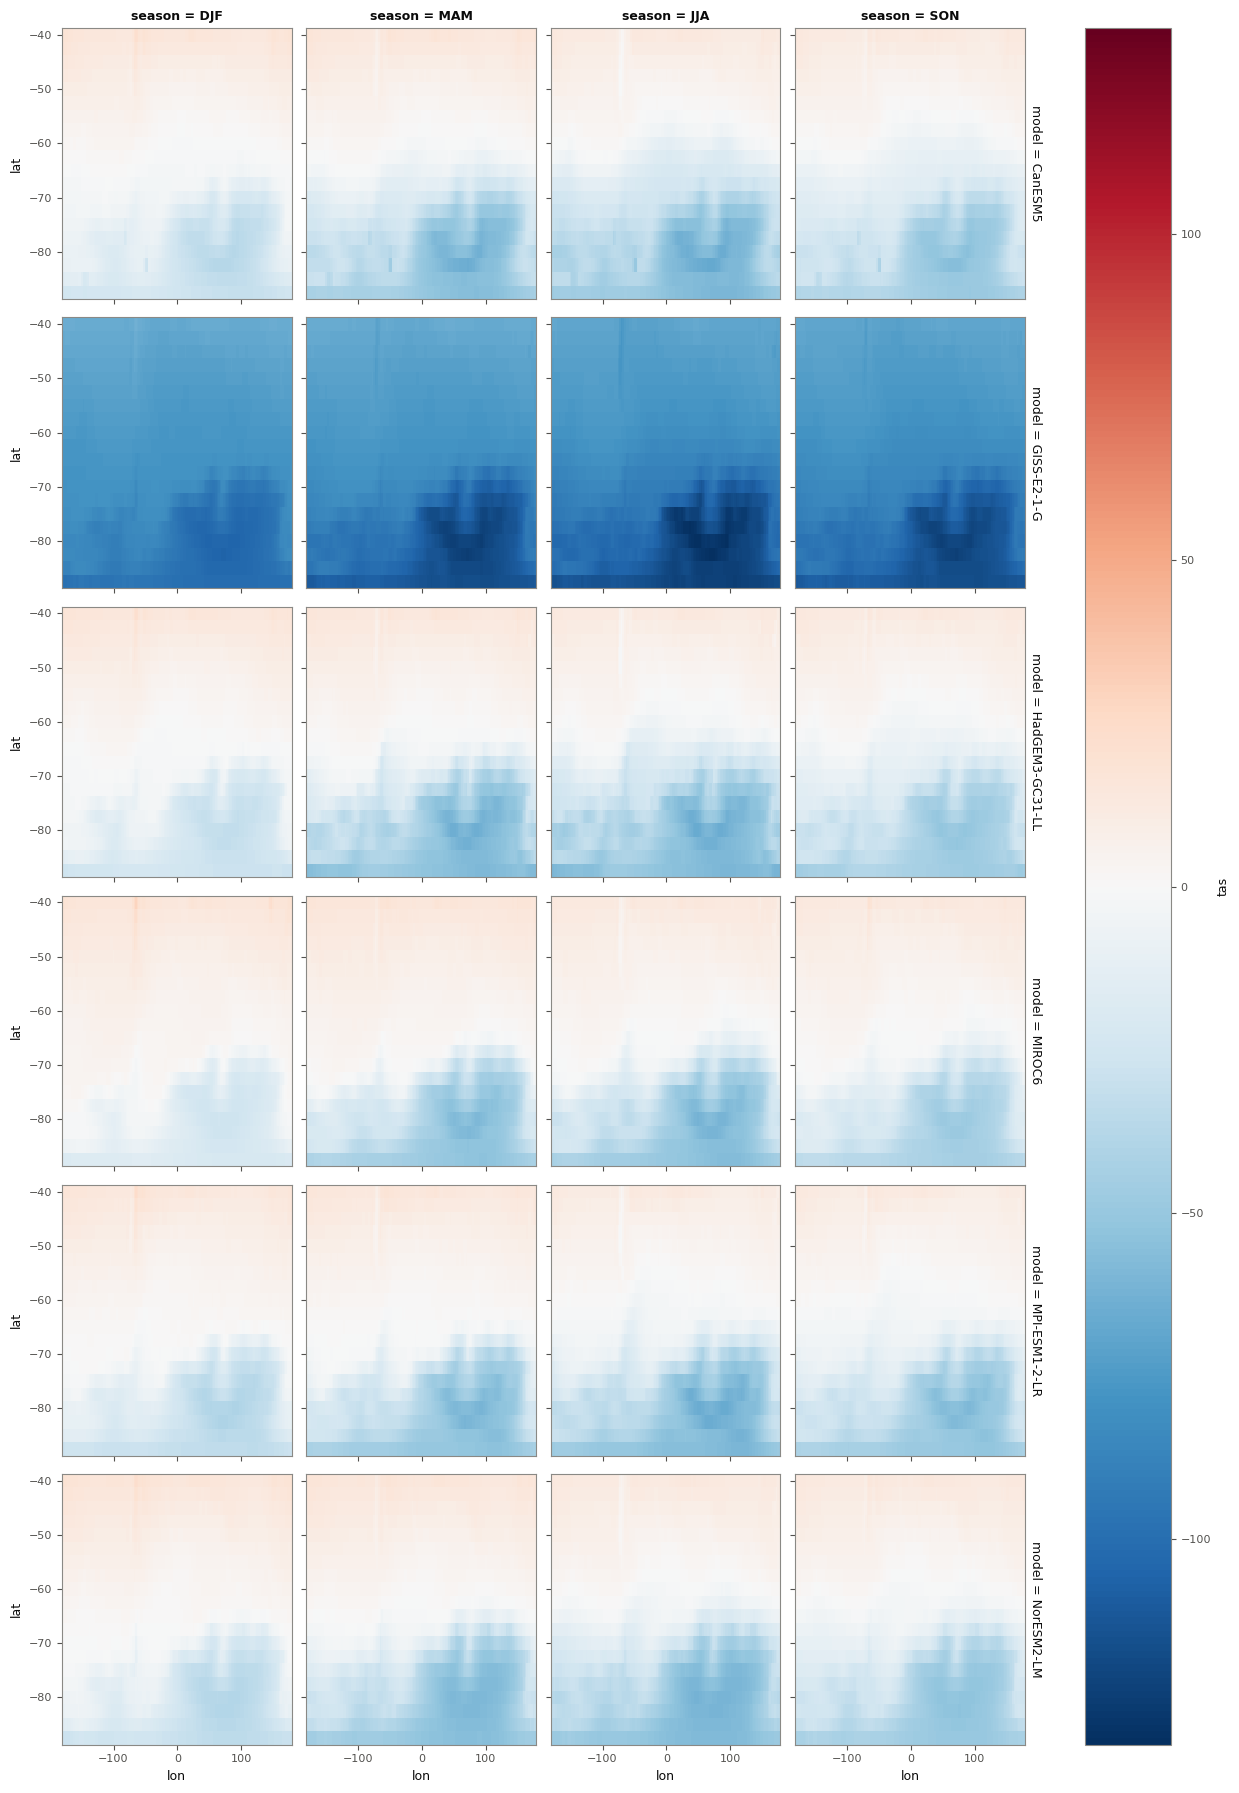

In [31]:
historical_climatology_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r');

In [32]:
#(t): Each model's climatology minus ERA5's
historical_bias_da = historical_climatology_da - era5_climatology_da

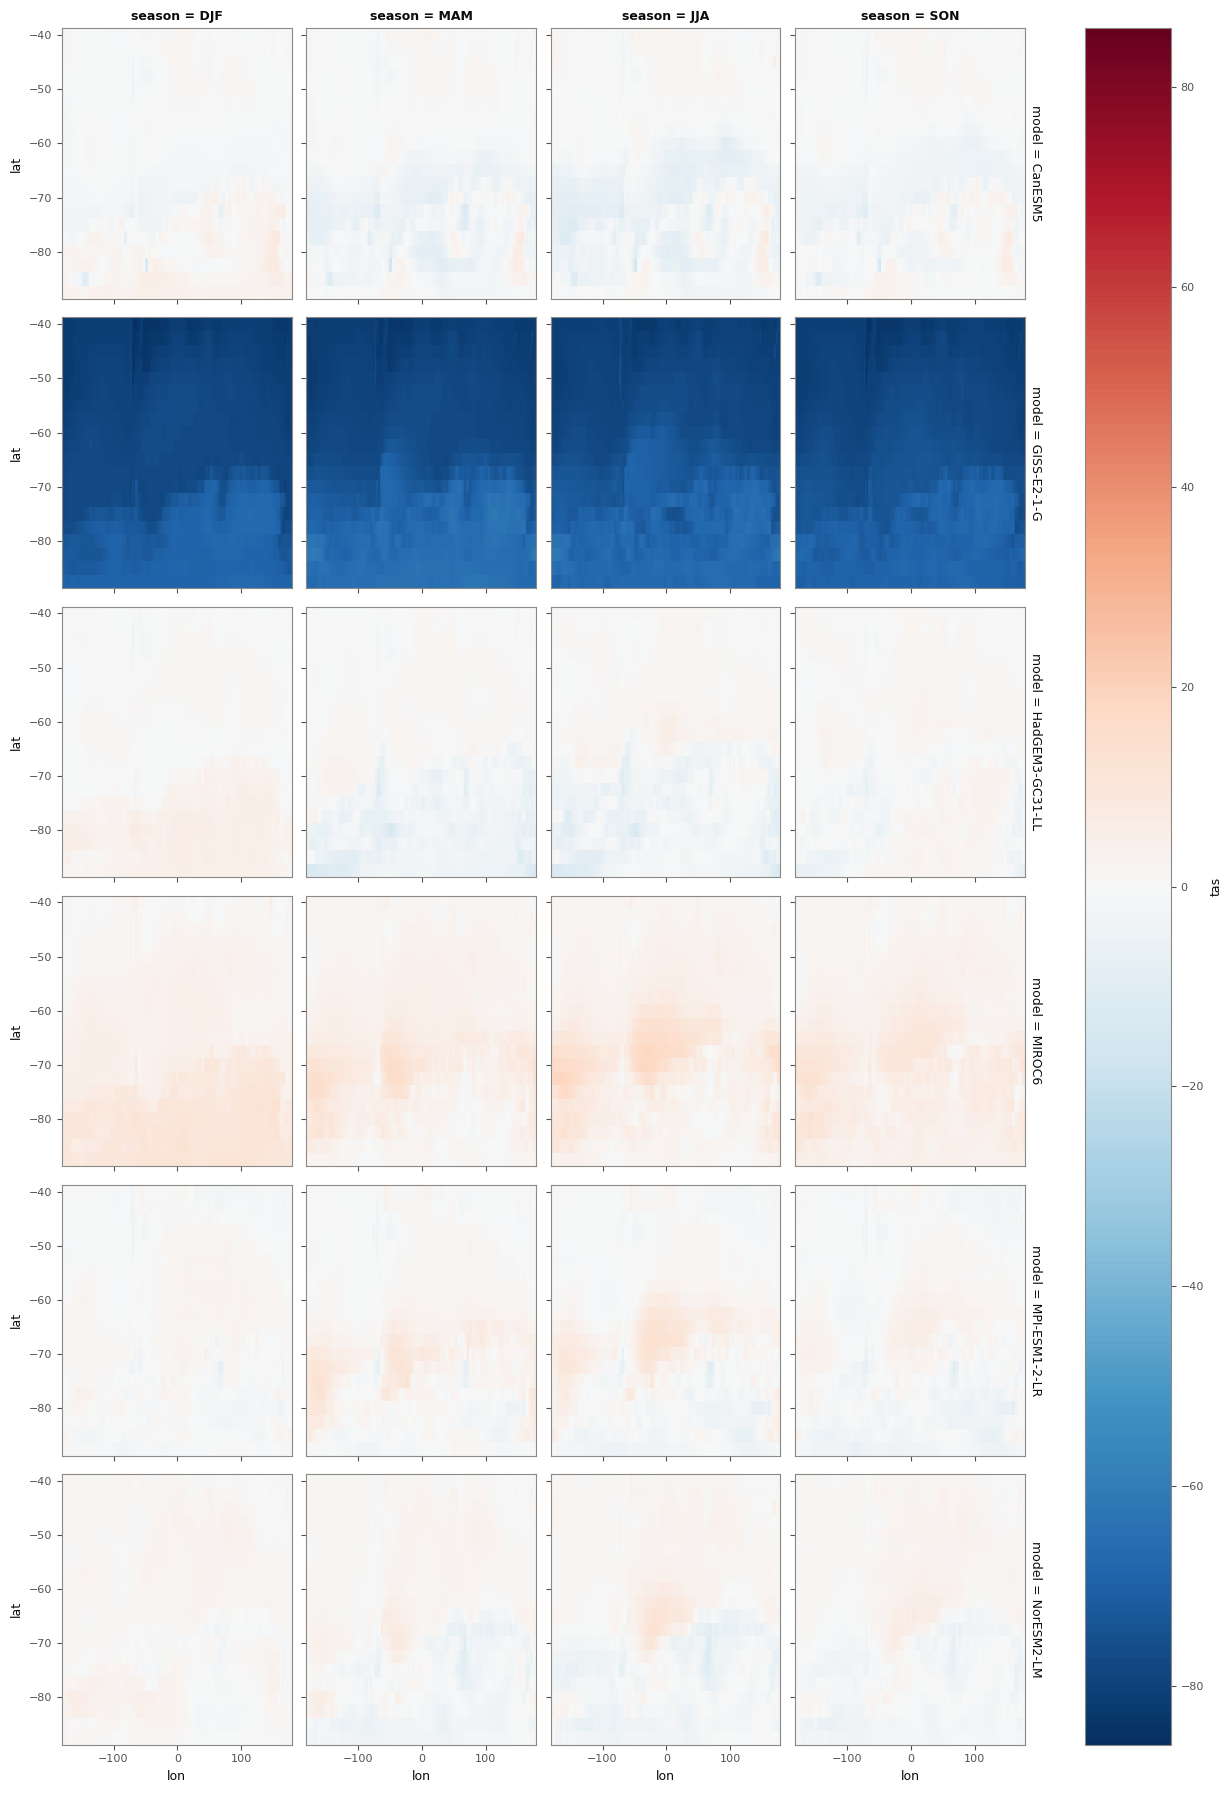

In [33]:
historical_bias_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r', center=0);

In [34]:
#(t): ERA5's climatology and each model's bias together, for plot_01's first look (polar maps)
first_look_ds = xr.Dataset({'era5_mean': era5_climatology_da, 'model_bias': historical_bias_da})
first_look_ds

<xarray.Dataset> Size: 324kB
Dimensions:     (lat: 20, season: 4, lon: 144, model: 6)
Coordinates:
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
Data variables:
    era5_mean   (lat, lon, season) float32 46kB -29.67 -44.06 ... 10.95 12.92
    model_bias  (lat, lon, season, model) float32 276kB 4.043 -69.45 ... 1.254

In [35]:
#(t): Saved for plot_01
first_look_path = RESULTS_DIR / 'first_look.zarr'
first_look_ds.to_zarr(first_look_path, mode='w')
first_look_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/first_look.zarr')

In [36]:
#(t): Each member's year-to-year standard deviation
historical_member_std_tree = historical_eval_tree.std('year')

In [37]:
#(t): averaged over the members
historical_std_tree = historical_member_std_tree.mean('member')

In [38]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_std_ds = datatree.tree_to_dataset(historical_std_tree, dims=['model', 'experiment']).load()
historical_std_da = historical_std_ds[VARIABLE.name].sel(experiment='historical', drop=True)

CPU times: user 4.49 s, sys: 7.42 s, total: 11.9 s
Wall time: 1.94 s


In [39]:
#(t): Each model's spread over ERA5's: above 1, the model varies more from year to year than ERA5
historical_std_ratio_da = historical_std_da / era5_std_da

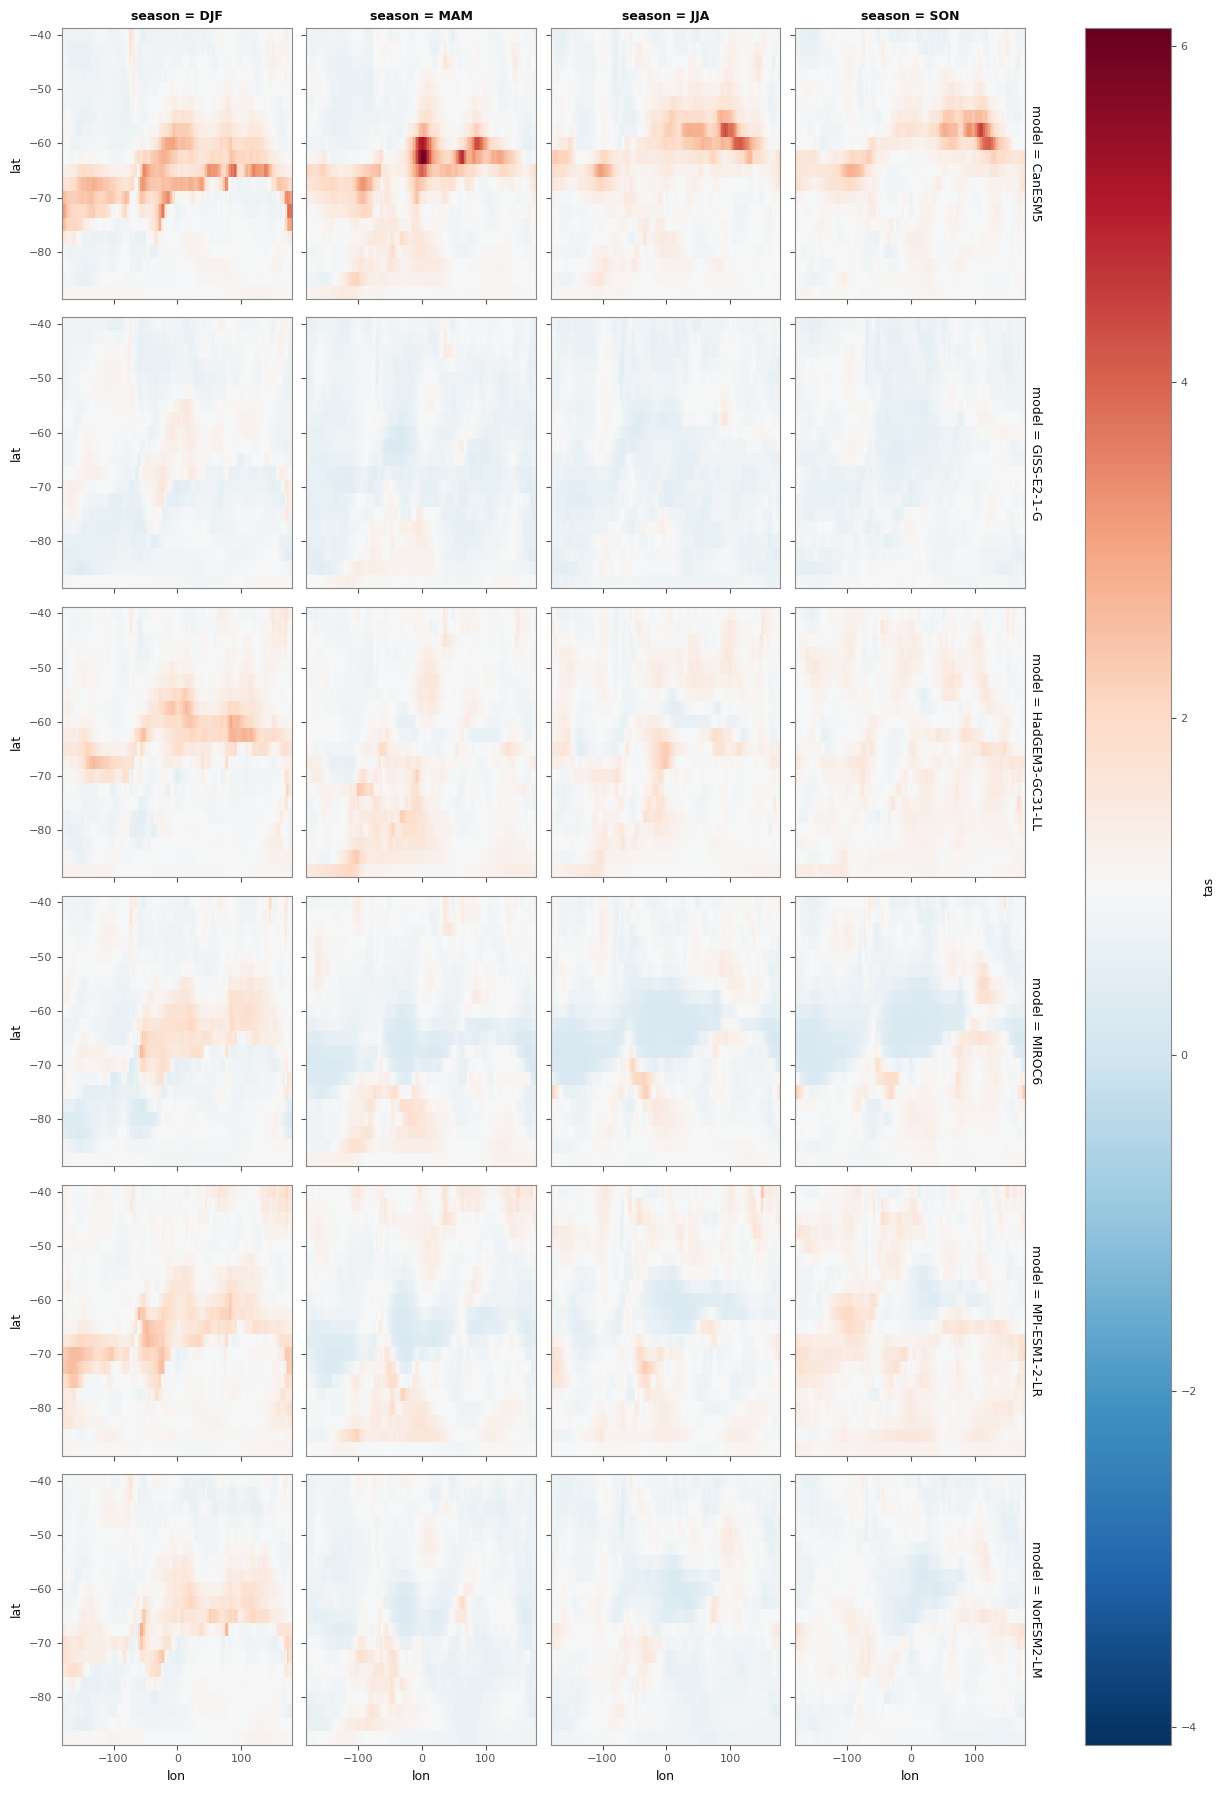

In [40]:
historical_std_ratio_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r', center=1);

In [41]:
#(t): Each model's historical ensemble mean, every year
historical_ensemble_mean_tree = historical_tree.mean('member')

In [42]:
#(t): In one DataArray, on (model, year, season, lat, lon)
historical_ensemble_mean_ds = datatree.tree_to_dataset(historical_ensemble_mean_tree, dims=['model', 'experiment'])
historical_ensemble_mean_da = historical_ensemble_mean_ds[VARIABLE.name].sel(experiment='historical', drop=True)

In [43]:
#(t): south of 60°S, in the seasons' order
historical_south_da = historical_ensemble_mean_da.sel(season=SEASONS, lat=slice(None, -60))

In [44]:
%%time
#(t): its area mean in every year (cos-latitude weighted)
historical_area_weights_da = np.cos(np.deg2rad(historical_south_da.lat))
historical_area_mean_da = historical_south_da.weighted(historical_area_weights_da).mean(['lat', 'lon']).load()

CPU times: user 2.67 s, sys: 5.12 s, total: 7.78 s
Wall time: 1.77 s


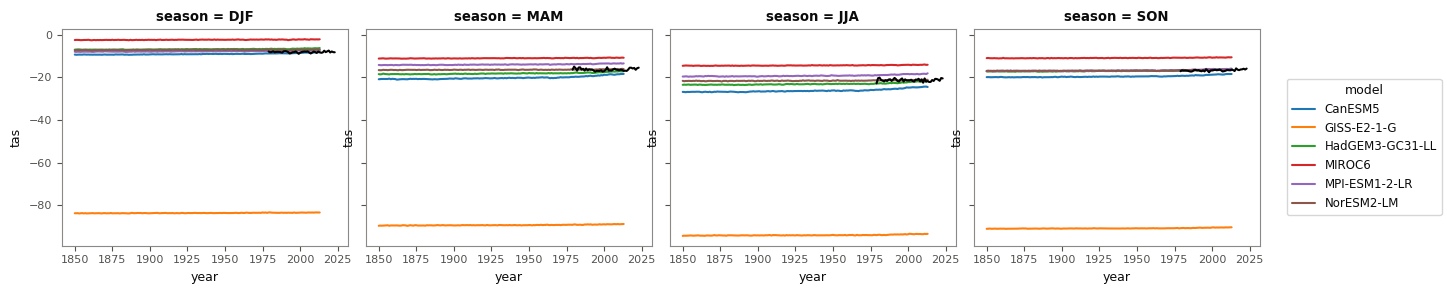

In [45]:
#(t): The models' ensemble means (colours) and ERA5 (black), one panel per season
fg = historical_area_mean_da.plot(x='year', hue='model', col='season')
for ax, season in zip(fg.axs.flat, SEASONS):
    era5_area_mean_da.sel(season=season).plot(ax=ax, color='k')

### One model's experiments

In [46]:
#(t): EXAMPLE_MODEL's every experiment, over SATELLITE_YEAR_RANGE, in the seasons' order
model_eval_tree = lesfmip_season_tree[EXAMPLE_MODEL].sel(year=SATELLITE_YEAR_RANGE, season=SEASONS)

In [47]:
#(t): Each experiment's climatology: the mean over the years and the members
model_climatology_tree = model_eval_tree.mean(['year', 'member'])

In [48]:
%%time
#(t): In one DataArray, on (experiment, season, lat, lon)
model_climatology_ds = datatree.tree_to_dataset(model_climatology_tree, dims=['experiment']).load()
model_climatology_da = model_climatology_ds[VARIABLE.name]

CPU times: user 2.21 s, sys: 3.35 s, total: 5.55 s
Wall time: 2.24 s


In [49]:
#(t): Each experiment's climatology minus hist-nat's, over the same years
model_difference_da = model_climatology_da - model_climatology_da.sel(experiment='hist-nat')

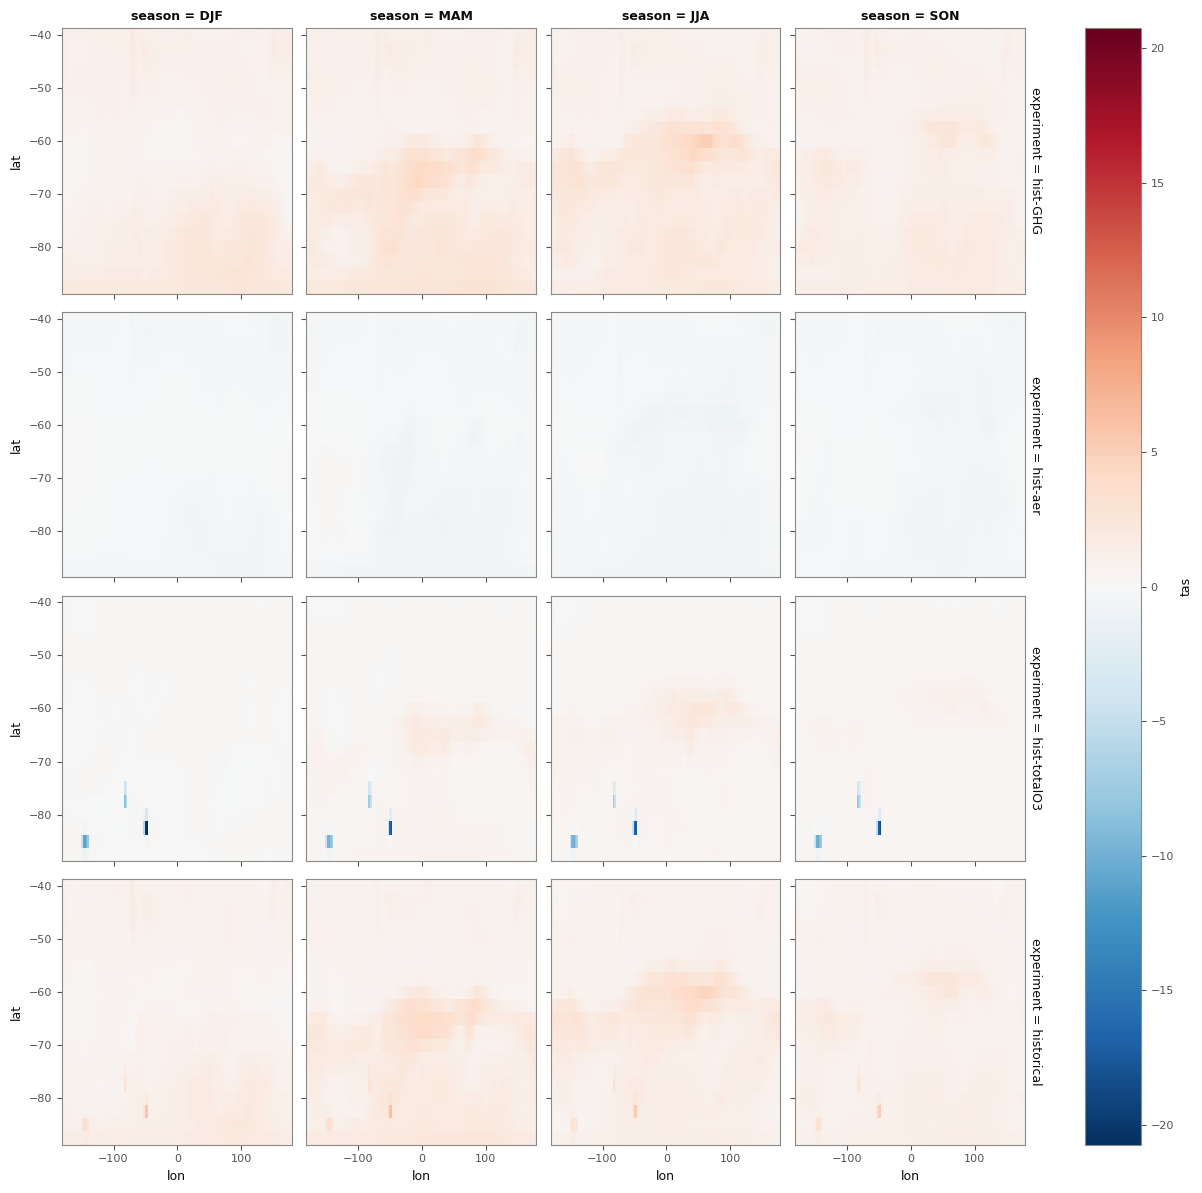

In [50]:
#(t): Quick look: each experiment's climatology minus hist-nat's, every season
model_difference_da.drop_sel(experiment='hist-nat').plot(x='lon', y='lat', row='experiment', col='season',
                                                         cmap='RdBu_r', center=0);

# Part 1: Is Each Model Consistent with ERA5?

Every test asks one question: *could ERA5 be one more member of the historical ensemble?* If a model simulates both the forced response (the **signal**) and the internal variability (the **noise**) correctly, ERA5 is statistically indistinguishable from any one member. So each test computes the same statistic for ERA5 and for every member, and asks where ERA5 falls among the members (Suarez-Gutierrez, Milinski & Maher, 2021, *Clim. Dyn.*, [doi:10.1007/s00382-021-05821-w](https://doi.org/10.1007/s00382-021-05821-w)). The members are the null distribution, so no shape is assumed, and each member is exactly as long as ERA5.

First at one grid point, then on the maps (section 7 and 8) and in regional means (section 9).

## Data at the Point

Each model's historical members and ERA5 over `SATELLITE_YEAR_RANGE`. The models stay in a DataTree, each with its own members; ERA5 is one DataArray.

In [51]:
#(t): LESFMIP over the years shared with ERA5
lesfmip_obs_tree = lesfmip_season_tree.sel(year=SATELLITE_YEAR_RANGE)

In [52]:
#(t): Each model's historical members at the point, on (member, year, season)
historical_point_tree = lesfmip_obs_tree.match('*/historical').sel(SAMPLE_LAT_LON).load()
historical_point_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 36kB -31.74 -57.74 ... -52.73 -45.67
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 35kB -273.1 -273.1 ... -273.1 -273.1
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, year: 35, season: 4)
│           Coordinates:
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon      float64 8B 120.0
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 24kB -32.66 -58.42 ... -54.74 -49.95
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, year, season) float32 31kB -27.72 -57.56 ... -51.74 -43.94
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 28kB -22.22 -52.98 ... -48.27 -41.32
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, year: 35, season: 4)
            Coordinates:
                lon      float64 8B 120.0
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
                lat      float64 8B -82.5
              * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, year, season) float32 29kB -34.95 -56.32 ... -52.23 -47.02

In [53]:
#(t): ERA5 at the point over the same years, on (year, season)
era5_point_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE).sel(SAMPLE_LAT_LON)
era5_point_da

<xarray.DataArray 'tas' (year: 35, season: 4)> Size: 560B
-32.97 -55.57 -51.88 -45.79 -33.46 -53.79 ... -46.57 -33.87 -50.94 -51.86 -43.27
Coordinates:
    lat      float64 8B -82.5
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013

In [54]:
#(t): Check: every model has the same years as ERA5, and nothing is missing (the tests compare the same samples)
{node.parent.name: (int(node.year.min()), int(node.year.max()), int(node['tas'].isnull().sum()))
 for node in historical_point_tree.leaves}, (int(era5_point_da.year.min()), int(era5_point_da.year.max()),
                                             int(era5_point_da.isnull().sum()))

({'CanESM5': (1979, 2013, 0),
  'GISS-E2-1-G': (1979, 2013, 0),
  'NorESM2-LM': (1979, 2013, 0),
  'HadGEM3-GC31-LL': (1979, 2013, 0),
  'MIROC6': (1979, 2013, 0),
  'MPI-ESM1-2-LR': (1979, 2013, 0)},
 (1979, 2013, 0))

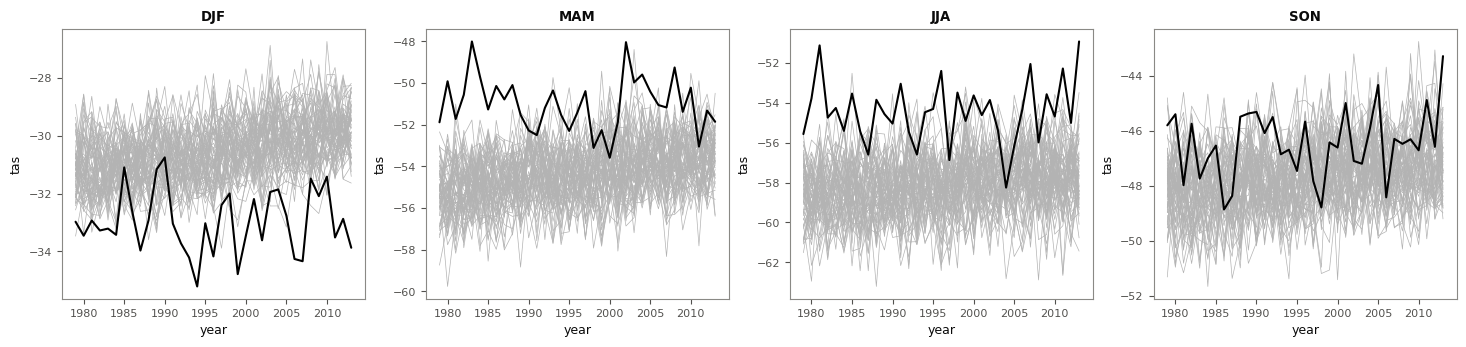

In [55]:
#(t): Quick look: EXAMPLE_MODEL's members (grey) and ERA5 (black), every season
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)
for ax, season in zip(axes, SEASONS):
    historical_point_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season=season).plot.line(ax=ax, x='year',
                                                                                           hue='member',
                                                                                    add_legend=False, color='0.7', lw=0.5)
    era5_point_da.sel(season=season).plot(ax=ax, color='k')
    ax.set_title(season)

In [56]:
#(t): Each model's hist-nat members at the point too, as context for plot_01's time series
histnat_point_tree = lesfmip_obs_tree.match('*/hist-nat').sel(SAMPLE_LAT_LON).load()
histnat_point_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/hist-nat
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, year, season) float32 28kB -30.76 -61.05 ... -58.24 -49.38
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/hist-nat
│           Dimensions:  (member: 20, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat      float64 8B -82.5
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│           Data variables:
│               tas      (member, year, season) float32 11kB -32.84 -61.18 ... -55.29 -52.48
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/hist-nat
│           Dimensions:  (member: 23, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, year, season) float32 13kB -34.6 -57.85 ... -54.57 -49.5
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/hist-nat
│           Dimensions:  (member: 60, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat      float64 8B -82.5
│             * member   (member) object 480B 'r10i1p1f3' 'r11i1p1f3' ... 'r9i1p1f3'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 34kB -28.42 -56.83 ... -55.54 -44.74
├── Group: /MIROC6
│   └── Group: /MIROC6/hist-nat
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lat      float64 8B -82.5
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│               lon      float64 8B 120.0
│           Data variables:
│               tas      (member, year, season) float32 28kB -23.61 -57.93 ... -53.11 -44.45
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/hist-nat
            Dimensions:  (member: 30, year: 35, season: 4)
            Coordinates:
                lon      float64 8B 120.0
              * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
                lat      float64 8B -82.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * member   (member) object 240B 'r10i1p1f2' 'r11i1p1f2' ... 'r9i1p1f2'
            Data variables:
                tas      (member, year, season) float32 17kB -36.47 -62.35 ... -56.92 -52.0

In [57]:
#(t): Saved for plot_01: each model's historical members at the point
historical_point_path = RESULTS_DIR / 'historical_point.zarr'
historical_point_tree.to_zarr(historical_point_path, mode='w')
historical_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/historical_point.zarr')

In [58]:
#(t): ... their hist-nat members
histnat_point_path = RESULTS_DIR / 'histnat_point.zarr'
histnat_point_tree.to_zarr(histnat_point_path, mode='w')
histnat_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/histnat_point.zarr')

In [59]:
#(t): ... and ERA5
era5_point_path = RESULTS_DIR / 'era5_point.zarr'
era5_point_da.to_dataset(name='tas').to_zarr(era5_point_path, mode='w')
era5_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/era5_point.zarr')

## Three Treatments

Each series (every member and ERA5, separately, in each season) is treated in the same way, so they all lose the same things with the same sampling noise:

| Treatment | Removed from each series | A test of it then sees |
|---|---|---|
| raw values | nothing | the climatology; a mean-state bias dominates |
| anomalies | its own mean over the years | the forced trend (signal) and the variability (noise) |
| detrended | its own least-squares line | the variability (noise) only |

In [60]:
#(t): Anomalies: each member minus its own mean over the years
historical_anomaly_tree = historical_point_tree - historical_point_tree.mean('year')

In [61]:
#(t): ... and ERA5 minus its own
era5_anomaly_da = era5_point_da - era5_point_da.mean('year')

In [62]:
#(t): Detrended: each member minus its own least-squares line through the years (ev.detrend)
historical_detrended_tree = historical_point_tree.map_over_datasets(skip_empty(ev.detrend))

In [63]:
#(t): ... and ERA5 minus its own
era5_detrended_da = ev.detrend(era5_point_da)

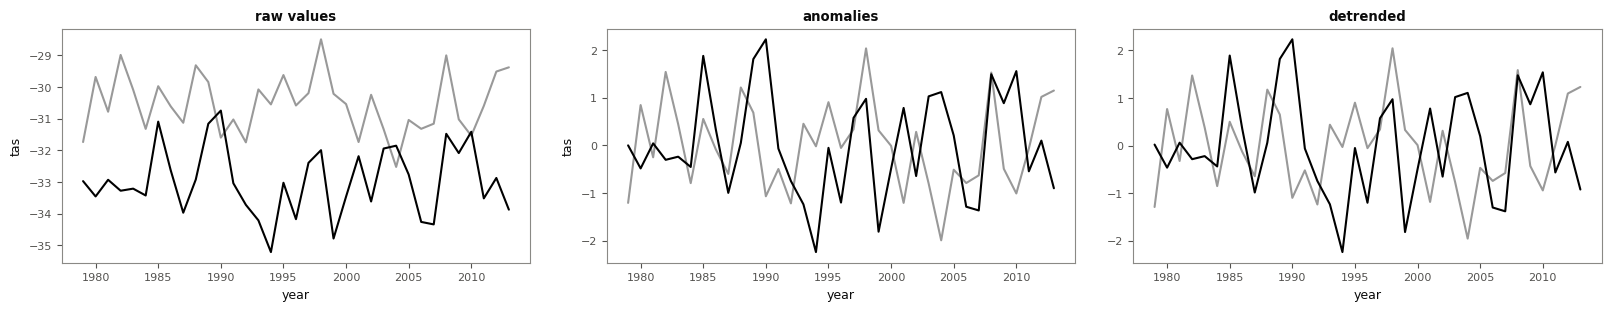

In [64]:
#(t): Quick look: the three treatments of EXAMPLE_MODEL's first member (grey) and ERA5 (black) at the point, in DJF
first_member_da = historical_point_tree[EXAMPLE_MODEL]['historical']['tas'].isel(member=0)
first_anomaly_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas'].isel(member=0)
first_detrended_da = historical_detrended_tree[EXAMPLE_MODEL]['historical']['tas'].isel(member=0)
fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharex=True, layout='constrained')
for ax, member_series_da, era5_series_da, treatment in zip(
        axes, [first_member_da, first_anomaly_da, first_detrended_da],
        [era5_point_da, era5_anomaly_da, era5_detrended_da], ['raw values', 'anomalies', 'detrended']):
    member_series_da.sel(season='DJF').plot(ax=ax, color='0.6')
    era5_series_da.sel(season='DJF').plot(ax=ax, color='k')
    ax.set_title(treatment)

## Where ERA5 Falls among the Members

Every test below ends the same way: the statistic of every model's members and ERA5's go to `ev.locate` (one model at a time, by going through the leaves of the tree), which returns for each season ERA5's value, the members' values and their 5%, 50% and 95%, ERA5's **percentile** among them (ties count half), the two-sided **p-value** (twice the smaller tail, ERA5 counted as one more member: 2 × (members at or beyond ERA5 on that side + 1) / (N + 1)), the **verdict** (−1 ERA5 below the members, +1 above, 0 not flagged; flagged when p < 0.1, i.e. ERA5 outside the members' 5–95%) and whether the model has enough members to flag anything (**testable**: N ≥ 20).

## Moment Test

The first four moments of each series: the **mean** of the raw values, and the **standard deviation**, **skewness** and **excess kurtosis** of the detrended values, so the 1979–2013 warming neither widens the spread nor bends the shape. To test a moment on other values, start its first cell from another tree (`historical_point_tree`, `historical_anomaly_tree` or `historical_detrended_tree`, and the matching ERA5), and change its treatment where the four are put together.

### Mean (raw values)

In [65]:
#(t): Each member's mean over the years, on (member, season)
historical_mean_tree = historical_point_tree.mean('year')

In [66]:
#(t): ERA5's
era5_mean_da = era5_point_da.mean('year')

In [67]:
#(t): Where ERA5's falls among each model's members
mean_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_mean_da) for node in historical_mean_tree.leaves
})

### Standard deviation (detrended)

In [68]:
#(t): The standard deviation of each member's detrended values, on (member, season)
historical_std_tree = historical_detrended_tree.std('year', ddof=1)

In [69]:
#(t): ERA5's
era5_std_da = era5_detrended_da.std('year', ddof=1)

In [70]:
#(t): Where ERA5's falls among each model's members
std_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_std_da) for node in historical_std_tree.leaves
})

### Skewness (detrended)

In [71]:
#(t): ev.skewness: the plain moment estimator; > 0 when the warm tail is longer
historical_skewness_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.skewness))

In [72]:
#(t): ERA5's
era5_skewness_da = ev.skewness(era5_detrended_da)

In [73]:
#(t): Where ERA5's falls among each model's members
skewness_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_skewness_da) for node in historical_skewness_tree.leaves
})

### Excess kurtosis (detrended)

In [74]:
#(t): ev.excess_kurtosis: 0 for a normal distribution, > 0 for heavier tails
historical_kurtosis_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.excess_kurtosis))

In [75]:
#(t): ERA5's
era5_kurtosis_da = ev.excess_kurtosis(era5_detrended_da)

In [76]:
#(t): Where ERA5's falls among each model's members
kurtosis_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_kurtosis_da) for node in historical_kurtosis_tree.leaves
})

### All four

In [77]:
#(t): Each model's four tests along a statistic dim
moment_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), std_test_tree[node.path].to_dataset(),
                          skewness_test_tree[node.path].to_dataset(), kurtosis_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'skewness', 'kurtosis']))
    for node in mean_test_tree.leaves
})

In [78]:
#(t): With the treatment each moment was computed on, for plot_01's labels
moment_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in moment_test_tree.leaves
})
moment_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 4, season: 4, member: 65)
│           Coordinates:
│               lat         float64 8B -82.5
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon         float64 8B 120.0
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -30.53 ... -0.4231
│               lower       (statistic, season) float64 128B -31.0 -58.55 ... -0.9818 -1.007
│               median      (statistic, season) float64 128B -30.53 -58.08 ... -0.3695
│               upper       (statistic, season) float64 128B -30.12 -57.55 ... 1.034 0.6424
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 70.77 30.77
│               pvalue      (statistic, season) float64 128B 0.0303 0.0303 ... 0.6061 0.6364
│               verdict     (statistic, season) float64 128B -1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 4, season: 4, member: 63)
│           Coordinates:
│               lat         float64 8B -82.5
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon         float64 8B 120.0
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -273.1 -273.1 ... nan
│               lower       (statistic, season) float64 128B -273.1 -273.1 ... -1.125
│               median      (statistic, season) float64 128B -33.27 -60.47 ... -0.235
│               upper       (statistic, season) float64 128B -32.26 -59.65 ... 1.771 1.849
│               percentile  (statistic, season) float64 128B 63.49 100.0 ... 53.33 37.78
│               pvalue      (statistic, season) float64 128B 0.75 0.03125 ... 0.9565 0.7826
│               verdict     (statistic, season) float64 128B 0.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:     (statistic: 4, season: 4, member: 43)
│           Coordinates:
│               lat         float64 8B -82.5
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon         float64 8B 120.0
│             * member      (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 6kB -33.08 -56.88 ... 0.772
│               lower       (statistic, season) float64 128B -33.7 -57.64 ... -1.005 -0.8904
│               median      (statistic, season) float64 128B -33.42 -57.27 ... -0.2369
│               upper       (statistic, season) float64 128B -32.98 -56.82 ... 1.369 0.8152
│               percentile  (statistic, season) float64 128B 97.67 100.0 ... 60.47 27.91


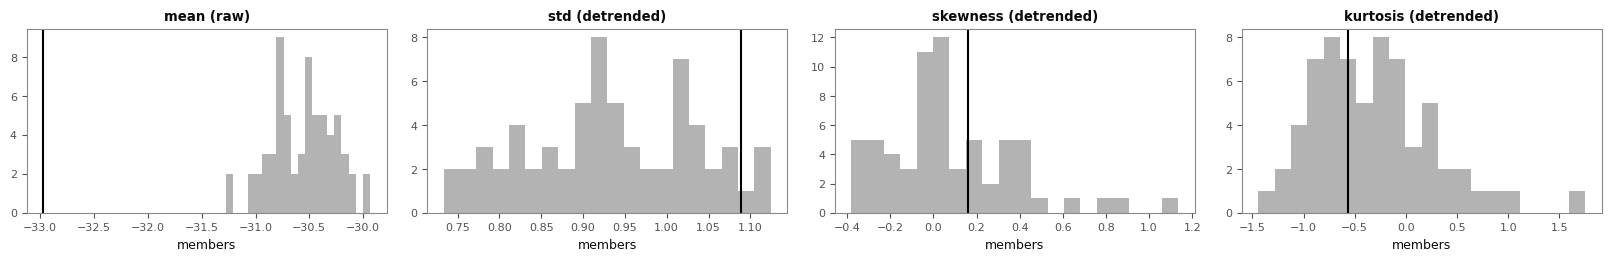

In [79]:
#(t): Quick look: EXAMPLE_MODEL's members (histogram) and ERA5 (black) for each moment, in DJF
example_moments_ds = moment_test_tree[EXAMPLE_MODEL]['historical'].to_dataset().sel(season='DJF')
fig, axes = plt.subplots(1, 4, figsize=(16, 2.5), layout='constrained')
for ax, statistic in zip(axes, example_moments_ds['statistic'].values):
    example_moments_ds['members'].sel(statistic=statistic).plot.hist(ax=ax, bins=20, color='0.7')
    ax.axvline(float(example_moments_ds['era5'].sel(statistic=statistic)), color='k')
    ax.set_title(f"{statistic} ({example_moments_ds['treatment'].sel(statistic=statistic).item()})")

In [80]:
#(t): Saved for plot_01
moment_test_path = RESULTS_DIR / 'moment_test.zarr'
moment_test_tree.to_zarr(moment_test_path, mode='w')
moment_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/moment_test.zarr')

## Other Statistics

Not moments, but tested in exactly the same way:

| Statistic | Of | What it measures |
|---|---|---|
| trend | raw values | the least-squares trend per decade: the forced response (**signal**) |
| emergence | raw values | the S/N against itself: the change of a 25-year LOWESS curve from the start of the record to the end, over the std of the deviations from it |
| width | detrended | Q95 − Q05, whose forced change the response notebooks analyse (**noise**) |
| lower_tail, upper_tail | detrended | the cold tail Q50 − Q05 and the warm tail Q95 − Q50 |
| records_high, records_low | raw values | how many record highs and lows (1 + 1/2 + … + 1/35 ≈ 4.1 of each with no change) |
| lag1 | detrended | the lag-1 autocorrelation: the year-to-year memory |

### Trend

In [81]:
#(t): The least-squares trend, per decade
historical_trend_tree = historical_point_tree.map_over_datasets(skip_empty(ev.trend))

In [82]:
#(t): ERA5's
era5_trend_da = ev.trend(era5_point_da)

In [83]:
#(t): Where ERA5's falls among each model's members
trend_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_trend_da) for node in historical_trend_tree.leaves
})

### Emergence

In [84]:
#(t): The smoothed change over the record, over its own noise
historical_emergence_tree = historical_point_tree.map_over_datasets(skip_empty(ev.self_signal_to_noise))

In [85]:
#(t): ERA5's
era5_emergence_da = ev.self_signal_to_noise(era5_point_da)

In [86]:
#(t): Where ERA5's falls among each model's members
emergence_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_emergence_da) for node in historical_emergence_tree.leaves
})

### Width

In [87]:
#(t): Q95 - Q05
historical_width_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.quantile_width))

In [88]:
#(t): ERA5's
era5_width_da = ev.quantile_width(era5_detrended_da)

In [89]:
#(t): Where ERA5's falls among each model's members
width_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_width_da) for node in historical_width_tree.leaves
})

### Lower tail

In [90]:
#(t): Q50 - Q05
historical_lower_tail_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.lower_tail_width))

In [91]:
#(t): ERA5's
era5_lower_tail_da = ev.lower_tail_width(era5_detrended_da)

In [92]:
#(t): Where ERA5's falls among each model's members
lower_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_lower_tail_da) for node in historical_lower_tail_tree.leaves
})

### Upper tail

In [93]:
#(t): Q95 - Q50
historical_upper_tail_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.upper_tail_width))

In [94]:
#(t): ERA5's
era5_upper_tail_da = ev.upper_tail_width(era5_detrended_da)

In [95]:
#(t): Where ERA5's falls among each model's members
upper_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_upper_tail_da) for node in historical_upper_tail_tree.leaves
})

### Records high

In [96]:
#(t): Years warmer than every year before them
historical_records_high_tree = historical_point_tree.map_over_datasets(skip_empty(ev.record_highs))

In [97]:
#(t): ERA5's
era5_records_high_da = ev.record_highs(era5_point_da)

In [98]:
#(t): Where ERA5's falls among each model's members
records_high_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_records_high_da) for node in historical_records_high_tree.leaves
})

### Records low

In [99]:
#(t): Years colder than every year before them
historical_records_low_tree = historical_point_tree.map_over_datasets(skip_empty(ev.record_lows))

In [100]:
#(t): ERA5's
era5_records_low_da = ev.record_lows(era5_point_da)

In [101]:
#(t): Where ERA5's falls among each model's members
records_low_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_records_low_da) for node in historical_records_low_tree.leaves
})

### Lag1

In [102]:
#(t): The correlation of each year with the next, for every member of each model (ev.lag1_autocorrelation uses xr.corr,
#(t): which takes a DataArray, so it goes through the leaves of the tree)
historical_lag1_tree = xr.DataTree.from_dict({
    node.path: ev.lag1_autocorrelation(node['tas']).to_dataset(name='tas') for node in historical_detrended_tree.leaves
})

In [103]:
#(t): ERA5's
era5_lag1_da = ev.lag1_autocorrelation(era5_detrended_da)

In [104]:
#(t): Where ERA5's falls among each model's members
lag1_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_lag1_da) for node in historical_lag1_tree.leaves
})

### All of them together

In [105]:
#(t): Each model's eight tests along a statistic dim
statistic_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), emergence_test_tree[node.path].to_dataset(),
                          width_test_tree[node.path].to_dataset(), lower_tail_test_tree[node.path].to_dataset(),
                          upper_tail_test_tree[node.path].to_dataset(), records_high_test_tree[node.path].to_dataset(),
                          records_low_test_tree[node.path].to_dataset(), lag1_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['trend', 'emergence', 'width', 'lower_tail', 'upper_tail',
                                                       'records_high', 'records_low', 'lag1']))
    for node in trend_test_tree.leaves
})

In [106]:
#(t): With the treatment of each, for plot_01's labels
statistic_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'raw', 'detrended', 'detrended', 'detrended',
                                                                        'raw', 'raw', 'detrended']))
    for node in statistic_test_tree.leaves
})
statistic_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 8, season: 4, member: 65)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U12 384B 'trend' 'emergence' ... 'lag1'
│               treatment   (statistic) <U9 288B 'raw' 'raw' ... 'raw' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 256B 0.01296 0.1282 ... -0.04442
│               members     (statistic, member, season) float64 17kB -0.04846 ... -0.01292
│               lower       (statistic, season) float64 256B 0.1112 -0.1618 ... -0.2939
│               median      (statistic, season) float64 256B 0.4332 0.3684 ... -0.01288
│               upper       (statistic, season) float64 256B 0.6944 0.7645 ... 0.1557 0.1933
│               percentile  (statistic, season) float64 256B 1.538 21.54 0.0 ... 98.46 40.0
│               pvalue      (statistic, season) float64 256B 0.06061 0.4545 ... 0.8182
│               verdict     (statistic, season) float64 256B -1.0 0.0 -1.0 ... 0.0 1.0 0.0
│               testable    (statistic, season) float64 256B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 8, season: 4, member: 63)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U12 384B 'trend' 'emergence' ... 'lag1'
│               treatment   (statistic) <U9 288B 'raw' 'raw' ... 'raw' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 256B 0.01296 0.1282 ... -0.04442
│               members     (statistic, member, season) float64 16kB 0.0 0.0 0.0 ... nan nan
│               lower       (statistic, season) float64 256B -0.09403 -0.1822 ... -0.2552
│               median      (statistic, season) float64 256B 0.04392 0.0008862 ... -0.04509
│               upper       (statistic, season) float64 256B 0.5523 0.5188 ... 0.2276 0.2363
│               percentile  (statistic, season) float64 256B 47.62 60.32 ... 93.33 51.11
│               pvalue      (statistic, season) float64 256B 0.9688 0.8125 ... 0.1739 1.0
│               verdict     (statistic, season) float64 256B 0.0 0.0 -1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 256B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:     (statistic: 8, season: 4, member: 43)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * statistic   (statistic) <U12 384B 'trend' 'emergence' ... 'lag1'
│               treatment   (statistic) <U9 288B 'raw' 'raw' ... 'raw' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 256B 0.01296 0.1282 ... -0.04442
│               members     (statistic, member, season) float64 11kB 0.2048 ... -0.04165
│               lower       (statistic, season) float64 256B -0.1023 -0.09412 ... -0.3
│               median      (statistic, season) float64 256B 0.2048 0.1768 ... -0.04179
│               upper       (statistic, season) float64 256B 0.4822 0.4659 ... 0.136 0.2281
│               percentile  (statistic, season) float64 256B 18.6 30.23 ... 95.35 48.84
│               pvalue      (st

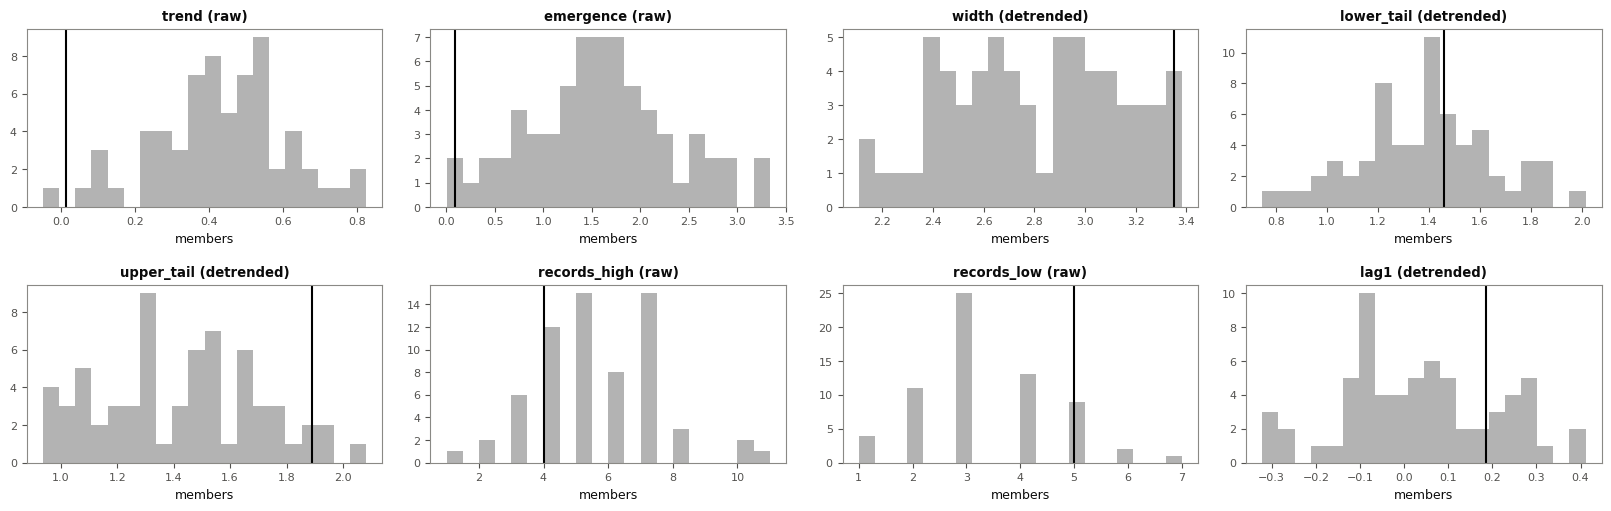

In [107]:
#(t): Quick look: EXAMPLE_MODEL's members (histogram) and ERA5 (black) for each statistic, in DJF
example_statistics_ds = statistic_test_tree[EXAMPLE_MODEL]['historical'].to_dataset().sel(season='DJF')
fig, axes = plt.subplots(2, 4, figsize=(16, 5), layout='constrained')
for ax, statistic in zip(axes.flat, example_statistics_ds['statistic'].values):
    example_statistics_ds['members'].sel(statistic=statistic).plot.hist(ax=ax, bins=20, color='0.7')
    ax.axvline(float(example_statistics_ds['era5'].sel(statistic=statistic)), color='k')
    ax.set_title(f"{statistic} ({example_statistics_ds['treatment'].sel(statistic=statistic).item()})")

In [108]:
#(t): Saved for plot_01
statistic_test_path = RESULTS_DIR / 'statistic_test.zarr'
statistic_test_tree.to_zarr(statistic_test_path, mode='w')
statistic_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/statistic_test.zarr')

## Rank Histograms

The test of Suarez-Gutierrez et al. (2021). Step by step on one model and season first, then `ev.rank_histogram_test` for every model.

1. Each year, ERA5's **rank**: how many members are below it.
2. The ranks of every year counted into a **histogram**. If ERA5 behaves like a member, every rank is equally likely and the histogram is flat.
3. With ~35 samples even a perfect model's histogram is not flat, so each member in turn is ranked against the other N − 1 (**pseudo-observations**): their histograms show how far from flat a perfect model's can be.
4. Each histogram summarised: the **dispersion** (the variance of the rank relative to a flat histogram: > 1 a U shape, too little spread; < 1 a dome, too much), how often ERA5 is outside every member, and the trend of the rank.
5. ERA5's summary located among the pseudo-observations'.

ERA5 is ranked against each of the N sub-ensembles that leave one member out, and those histograms averaged (`ev.leave_one_out_counts`), so it faces exactly the pseudo-observations' test.

In [109]:
#(t): EXAMPLE_MODEL's anomalies and ERA5's in DJF, the example season
season_members_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season='DJF')
season_era5_da = era5_anomaly_da.sel(season='DJF')

In [110]:
#(t): 1. ERA5's rank in each year (0 to N)
season_era5_rank_da = ev.ensemble_rank(season_members_da, season_era5_da)

In [111]:
#(t): 3. Each member's rank among the other N - 1, each year
season_pseudo_rank_da = ev.pseudo_observation_ranks(season_members_da)

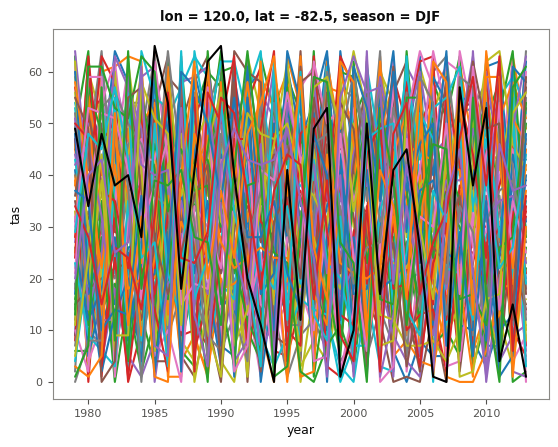

In [141]:
season_pseudo_rank_da.plot(hue='member', add_legend=False);
season_era5_rank_da.plot(color='black')

In [112]:
#(t): 2. and 3. The ranks counted over the years, on the same N bins
n_season_members = season_members_da.sizes['member']
season_era5_counts_da = ev.leave_one_out_counts(season_era5_rank_da, n_season_members, 'year')
season_pseudo_counts_da = ev.rank_counts(season_pseudo_rank_da, n_season_members, 'year')

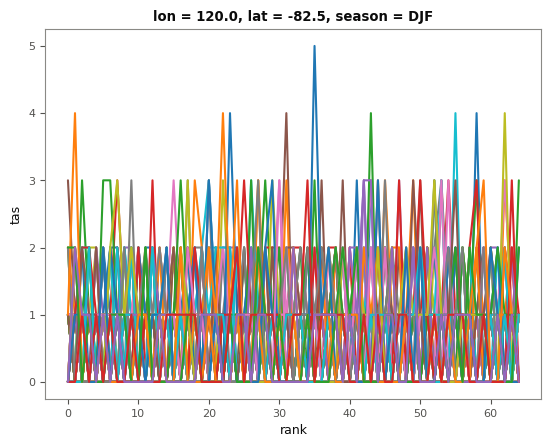

In [143]:
season_pseudo_counts_da.plot(hue='member', add_legend=False);

In [113]:
#(t): 4. Each histogram summarised
season_era5_summary_ds = ev.rank_statistics(season_era5_counts_da)
season_pseudo_summary_ds = ev.rank_statistics(season_pseudo_counts_da)

In [145]:
season_pseudo_summary_ds

<xarray.Dataset> Size: 3kB
Dimensions:     (member: 65)
Coordinates:
    lon         float64 8B 120.0
    lat         float64 8B -82.5
    season      <U3 12B 'DJF'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Data variables:
    below       (member) float64 520B 2.857 0.0 2.857 2.857 ... 5.714 0.0 0.0
    above       (member) float64 520B 2.857 0.0 0.0 0.0 ... 0.0 5.714 0.0 0.0
    outside     (member) float64 520B 5.714 0.0 2.857 2.857 ... 11.43 0.0 0.0
    mean_rank   (member) float64 520B 0.5013 0.4996 0.5 ... 0.4951 0.4996 0.5228
    dispersion  (member) float64 520B 1.217 0.9399 1.066 ... 1.249 0.7319 0.9432

In [114]:
#(t): 5. Where ERA5's dispersion falls among the pseudo-observations'
season_dispersion_test_ds = ev.locate(season_pseudo_summary_ds['dispersion'], season_era5_summary_ds['dispersion'])

In [136]:
season_dispersion_test_ds

<xarray.Dataset> Size: 1kB
Dimensions:     (member: 65)
Coordinates:
    lon         float64 8B 120.0
    lat         float64 8B -82.5
    season      <U3 12B 'DJF'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Data variables:
    era5        float64 8B 1.164
    members     (member) float64 520B 1.217 0.9399 1.066 ... 1.249 0.7319 0.9432
    lower       float64 8B 0.7748
    median      float64 8B 0.979
    upper       float64 8B 1.261
    percentile  float64 8B 76.92
    pvalue      float64 8B 0.4848
    verdict     float64 8B 0.0
    testable    float64 8B 1.0

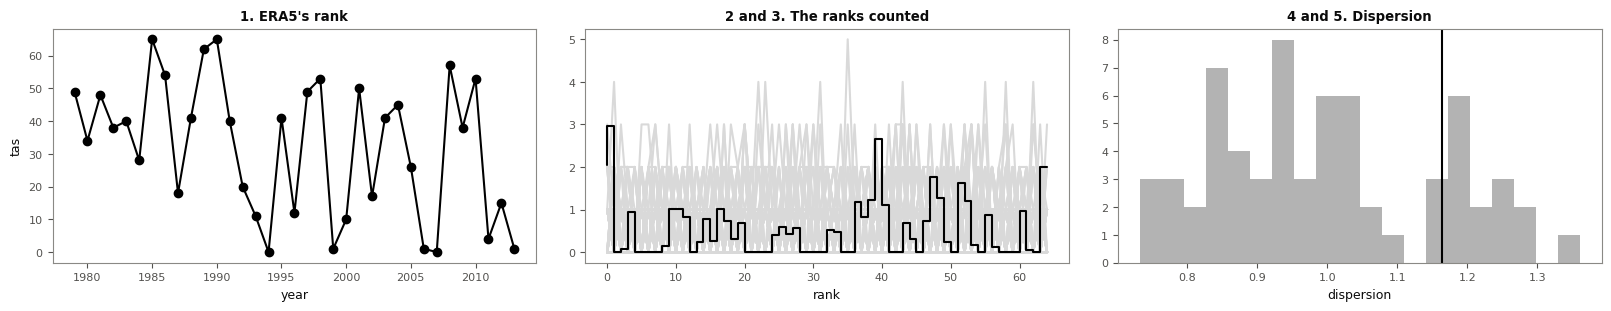

In [115]:
#(t): Quick look: the steps on EXAMPLE_MODEL's anomalies in DJF. ERA5's rank each year (1); the ranks counted,
#(t): ERA5's (black) and each pseudo-observation's (grey) (2 and 3); the dispersions, ERA5's (black) among the
#(t): pseudo-observations' (4 and 5)
fig, axes = plt.subplots(1, 3, figsize=(16, 3), layout='constrained')
season_era5_rank_da.plot(ax=axes[0], marker='o', color='k')
axes[0].set_title("1. ERA5's rank")
season_pseudo_counts_da.plot.line(ax=axes[1], x='rank', hue='member', add_legend=False, color='0.85')
season_era5_counts_da.plot.step(ax=axes[1], color='k')
axes[1].set_title('2 and 3. The ranks counted')
season_pseudo_summary_ds['dispersion'].plot.hist(ax=axes[2], bins=20, color='0.7')
axes[2].axvline(float(season_era5_summary_ds['dispersion']), color='k')
axes[2].set_title('4 and 5. Dispersion');

In [116]:
#(t): The same through ev.rank_histogram_test, which treats the raw values itself and tests every summary
anatomy_result_ds = ev.rank_histogram_test(historical_point_tree[EXAMPLE_MODEL]['historical']['tas'].sel(season='DJF'),
                                           era5_point_da.sel(season='DJF'), 'anomaly')
anatomy_result_ds

<xarray.Dataset> Size: 59kB
Dimensions:           (statistic: 6, member: 65, rank: 65, year: 35)
Coordinates:
    lon               float64 8B 120.0
    lat               float64 8B -82.5
    season            <U3 12B 'DJF'
  * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
  * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
    label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
    units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
    treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
  * rank              (rank) int64 520B 0 1 2 3 4 5 6 7 ... 58 59 60 61 62 63 64
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
Data variables: (12/13)
    era5              (statistic) float64 48B 1.164 11.56 ... 0.4954 -0.1176
    members           (statistic, member) float64 3kB 1.217 0.9399 ... 0.0105
    lower             (statistic) float64 48B 0.7748 0.0 0.0 0.0 0.4836 -0.09545
    median            (statistic) float64 48B 0.979 2.857 ... 0.4991 -0.003151
    upper             (statistic) float64 48B 1.261 8.0 5.714 ... 0.519 0.07656
    percentile        (statistic) float64 48B 76.92 100.0 98.46 ... 38.46 1.538
    ...                ...
    verdict           (statistic) float64 48B 0.0 1.0 1.0 0.0 0.0 -1.0
    testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
    obs_frequency     (rank) float64 520B 5.846 8.44 0.0 ... 0.1319 0.0 5.714
    pseudo_frequency  (rank, member) float64 34kB 2.857 0.0 2.857 ... 0.0 0.0
    obs_rank          (year) float64 280B 0.7538 0.5231 ... 0.2308 0.01538
    pseudo_rank       (member, year) float64 18kB 0.2656 0.9062 ... 0.5938
Attributes: (4)

In [117]:
#(t): Check: both give the same dispersion test
check_variables = ['era5', 'percentile', 'pvalue', 'verdict']
pd.DataFrame({'step by step': season_dispersion_test_ds[check_variables].to_pandas(),
              'ev.rank_histogram_test': anatomy_result_ds.sel(statistic='dispersion')[check_variables].to_pandas()})

,step by step,ev.rank_histogram_test
era5,1.164070,1.164070
percentile,76.923077,76.923077
pvalue,0.484848,0.484848
verdict,0.000000,0.000000


In [118]:
#(t): The anomalies, together for plot_01's figure of the method
rank_anatomy_ds = xr.Dataset({'members': season_members_da, 'era5': season_era5_da})

In [119]:
#(t): Saved for plot_01
rank_anatomy_data_path = RESULTS_DIR / 'rank_anatomy_data.zarr'
rank_anatomy_ds.to_zarr(rank_anatomy_data_path, mode='w')
rank_anatomy_data_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/rank_anatomy_data.zarr')

In [120]:
#(t): ... and the test
rank_anatomy_test_path = RESULTS_DIR / 'rank_anatomy_test.zarr'
anatomy_result_ds.to_zarr(rank_anatomy_test_path, mode='w')
rank_anatomy_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/rank_anatomy_test.zarr')

### Every model

The headline histograms pool the four seasons (four times the samples); the scorecard uses one per season.

In [121]:
#(t): Raw values, the four seasons pooled: ev.rank_histogram_test on each model's members (it needs each model's own
#(t): number of members), against ERA5
raw_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'raw', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})

In [122]:
#(t): Anomalies, the four seasons pooled
anomaly_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'anomaly', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})
anomaly_ranks_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:           (statistic: 6, member: 65, rank: 65, season: 4, year: 35)
│           Coordinates:
│               lon               float64 8B 120.0
│               lat               float64 8B -82.5
│             * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
│             * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
│               label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
│               units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
│               treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
│             * rank              (rank) int64 520B 0 1 2 3 4 5 6 7 ... 58 59 60 61 62 63 64
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│           Data variables: (12/13)
│               era5              (statistic) float64 48B 1.047 5.077 ... 0.5015 -0.08095
│               members           (statistic, member) float64 3kB 1.037 1.058 ... 0.002746
│               lower             (statistic) float64 48B 0.8815 0.7143 ... 0.49 -0.04405
│               median            (statistic) float64 48B 0.9985 2.857 ... 0.5 0.002746
│               upper             (statistic) float64 48B 1.096 6.143 ... 0.5098 0.0373
│               percentile        (statistic) float64 48B 72.31 93.85 84.62 93.85 56.92 0.0
│               ...                ...
│               verdict           (statistic) float64 48B 0.0 0.0 0.0 0.0 0.0 -1.0
│               testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
│               obs_frequency     (rank) float64 520B 2.209 4.264 1.418 ... 0.7473 2.868
│               pseudo_frequency  (rank, member) float64 34kB 2.143 2.857 ... 0.7143 0.0
│               obs_rank          (year, season) float64 1kB 0.7538 0.2923 ... 0.9846
│               pseudo_rank       (member, year, season) float64 73kB 0.2656 ... 0.8906
│           Attributes: (4)
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:           (statistic: 6, member: 63, rank: 63, season: 4, year: 35)
│           Coordinates:
│               lon               float64 8B 120.0
│               lat               float64 8B -82.5
│             * member            (member) object 504B 'r10i1p1f1' ... 'r9i1p5f1'
│             * statistic         (statistic) <U10 240B 'dispersion' ... 'rank_trend'
│               label             (statistic) <U17 408B 'Rank dispersion' ... 'Rank trend'
│               units             (statistic) <U7 168B '' '%' '%' '%' '' '/decade'
│               treatment         (statistic) <U7 168B 'anomaly' 'anomaly' ... 'anomaly'
│             * rank              (rank) int64 504B 0 1 2 3 4 5 6 7 ... 56 57 58 59 60 61 62
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│           Data variables: (12/13)
│               era5              (statistic) float64 48B 1.261 2.914 ... 0.4883 -0.02108
│               members           (statistic, member) float64 3kB 0.06908 ... -0.04369
│               lower             (statistic) float64 48B 0.06908 0.0 0.0 0.0 0.421 -0.04369
│               median            (statistic) float64 48B 1.316 3.571 ... 0.4969 0.001864
│               upper             (statistic) float64 48B 1.438 7.071 ... 0.5952 0.07066
│               percentile        (statistic) float64 48B 39.68 46.03 76.19 41.27 30.16 38.1
│               ...                ...
│               verdict           (statistic) float64 48B 0.0 0.0 0.0 0.0 0.0 0.0
│               testable          (statistic) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
│               obs_frequency     (rank) float64 504B 2.154 0.771 2.143 ... 2.88 0.7596
│  

In [123]:
#(t): Detrended anomalies, the four seasons pooled
detrended_ranks_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'detrended', pool_dims=('year', 'season'))
    for node in historical_point_tree.leaves
})

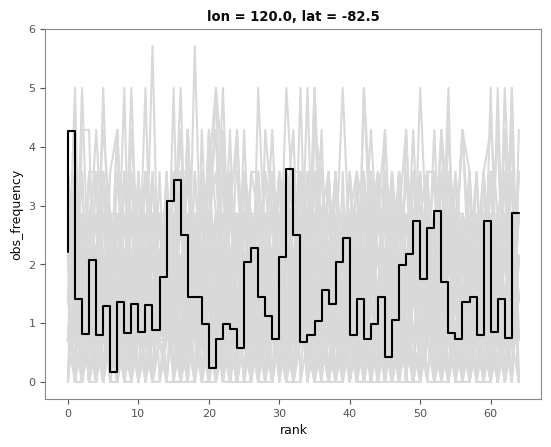

In [124]:
#(t): Quick look: EXAMPLE_MODEL's histogram of anomalies (bars: ERA5; grey: each pseudo-observation's)
anomaly_ranks_ds = anomaly_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset()
anomaly_ranks_ds['pseudo_frequency'].plot.line(x='rank', hue='member', add_legend=False, color='0.85')
anomaly_ranks_ds['obs_frequency'].plot.step(color='k');

In [125]:
#(t): One test per season, for the scorecard (without the histograms): anomalies
anomaly_ranks_seasonal_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'anomaly', pool_dims=('year',), keep_histograms=False)
    for node in historical_point_tree.leaves
})

In [126]:
#(t): ... and detrended anomalies
detrended_ranks_seasonal_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_test(node['tas'], era5_point_da, 'detrended', pool_dims=('year',),
                                      keep_histograms=False)
    for node in historical_point_tree.leaves
})

In [127]:
#(t): Saved for plot_01
raw_ranks_path = RESULTS_DIR / 'raw_ranks.zarr'
raw_ranks_tree.to_zarr(raw_ranks_path, mode='w')
raw_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/raw_ranks.zarr')

In [128]:
#(t): Saved for plot_01
anomaly_ranks_path = RESULTS_DIR / 'anomaly_ranks.zarr'
anomaly_ranks_tree.to_zarr(anomaly_ranks_path, mode='w')
anomaly_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/anomaly_ranks.zarr')

In [129]:
#(t): Saved for plot_01
detrended_ranks_path = RESULTS_DIR / 'detrended_ranks.zarr'
detrended_ranks_tree.to_zarr(detrended_ranks_path, mode='w')
detrended_ranks_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/detrended_ranks.zarr')

## Every Test in One Table

Each test's percentile, verdict and whether it could flag anything, without the members, so every model fits in one Dataset on (model, statistic, season): for plot_01's scorecard and signal-vs-noise diagram. Both rank tests have a dispersion, so those two are named for their treatment.

In [130]:
#(t): The moments' verdicts only (no members), every model, on (model, experiment, statistic, season)
moment_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                              for node in moment_test_tree.leaves})
moment_verdicts_ds = tree_to_dataset(moment_verdicts_tree, dims=['model', 'experiment'])

In [131]:
#(t): ... and the other statistics'
statistic_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                                 for node in statistic_test_tree.leaves})
statistic_verdicts_ds = tree_to_dataset(statistic_verdicts_tree, dims=['model', 'experiment'])

In [132]:
#(t): The rank trend and dispersion of the anomalies, verdicts only
anomaly_rank_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                                    for node in anomaly_ranks_seasonal_tree.leaves})
anomaly_rank_verdicts_ds = tree_to_dataset(anomaly_rank_verdicts_tree, dims=['model', 'experiment'])
anomaly_rank_verdicts_ds = anomaly_rank_verdicts_ds.sel(statistic=['rank_trend', 'dispersion']).drop_vars(['label', 'units'])
anomaly_rank_verdicts_ds = anomaly_rank_verdicts_ds.assign_coords(statistic=['rank_trend', 'dispersion (anomaly)'])

In [133]:
#(t): ... and the dispersion of the detrended anomalies
detrended_rank_verdicts_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['percentile', 'verdict', 'testable']]
                                                      for node in detrended_ranks_seasonal_tree.leaves})
detrended_rank_verdicts_ds = tree_to_dataset(detrended_rank_verdicts_tree, dims=['model', 'experiment'])
detrended_rank_verdicts_ds = detrended_rank_verdicts_ds.sel(statistic=['dispersion']).drop_vars(['label', 'units'])
detrended_rank_verdicts_ds = detrended_rank_verdicts_ds.assign_coords(statistic=['dispersion (detrended)'])

In [134]:
#(t): Everything along one statistic dim
eval_table_by_experiment_ds = xr.concat([moment_verdicts_ds, statistic_verdicts_ds, anomaly_rank_verdicts_ds,
                                         detrended_rank_verdicts_ds], dim='statistic')
eval_table_ds = eval_table_by_experiment_ds.sel(experiment='historical', drop=True)
#(c): tree_to_dataset leaves the model names as Python objects, which xarray will not put on an axis
eval_table_ds = eval_table_ds.assign_coords(model=eval_table_ds['model'].astype(str))
eval_table_ds

<xarray.Dataset> Size: 11kB
Dimensions:     (statistic: 15, season: 4, model: 6)
Coordinates:
    lat         float64 8B -82.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon         float64 8B 120.0
  * statistic   (statistic) <U22 1kB 'mean' 'std' ... 'dispersion (detrended)'
    treatment   (statistic) <U9 540B 'raw' 'detrended' ... 'anomaly' 'detrended'
  * model       (model) <U15 360B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
Data variables:
    percentile  (statistic, season, model) float64 3kB 0.0 63.49 ... 13.73 76.74
    verdict     (statistic, season, model) float64 3kB -1.0 0.0 -1.0 ... 0.0 0.0
    testable    (statistic, season, model) float64 3kB 1.0 1.0 1.0 ... 1.0 1.0

TypeError: Plotting requires coordinates to be numeric, boolean, or dates of type numpy.datetime64, datetime.datetime, cftime.datetime or pandas.Interval. Received data of type object instead.

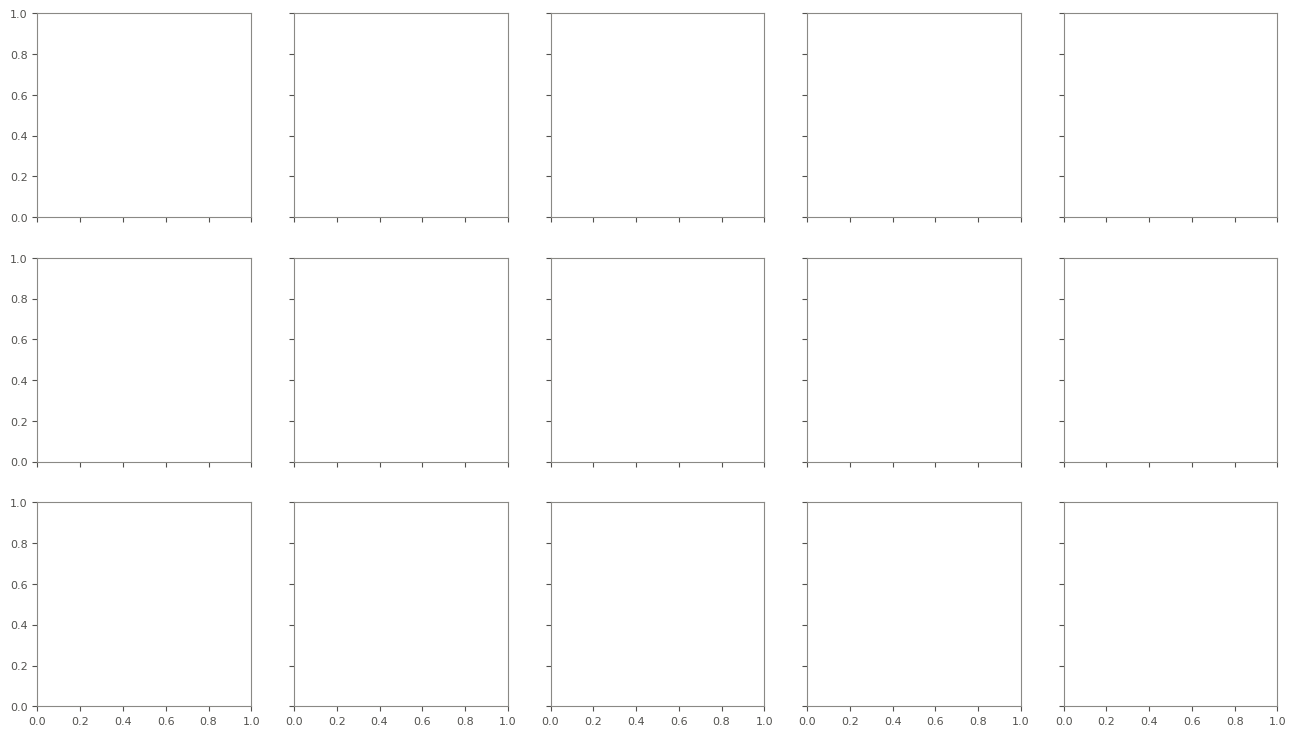

In [135]:
#(t): Quick look: ERA5's percentile among each model's members (50: in the middle; 0 or 100: beyond every member)
eval_table_ds['percentile'].sel(season=SEASONS).plot(x='season', y='model', col='statistic', col_wrap=5, vmin=0,
                                                     vmax=100, cmap='RdBu_r');

In [ ]:
#(t): Saved for plot_01
eval_table_path = RESULTS_DIR / 'eval_table.zarr'
eval_table_ds.to_zarr(eval_table_path, mode='w')
eval_table_path

## Toy Ensembles with a Known Answer

Before trusting the tests on real data: synthetic ensembles where we *know* what is wrong (`ev.simulate_ensemble`: 50 members and a pseudo-ERA5, 1979–2013, four seasons, each series trend × decades + noise × N(0, 1)). Pseudo-ERA5 always has a trend of 0.3 per decade and noise 1; each scenario of `ev.SCENARIOS` changes one thing about the model. plot_01 draws them.

In [ ]:
#(t): A toy ensemble and pseudo-ERA5 for each scenario, side by side on a scenario dim (all have 50 members)
demo_datasets = []
for settings in ev.SCENARIOS.values():
    demo_members_da, demo_era5_da = ev.simulate_ensemble(seed=3, **settings)
    demo_datasets.append(xr.Dataset({'members': demo_members_da, 'era5': demo_era5_da}))
demo_ds = xr.concat(demo_datasets, dim=xr.Variable('scenario', list(ev.SCENARIOS)))

In [ ]:
#(t): Quick look: each scenario's members (grey) and pseudo-ERA5 (black) in DJF
fg = demo_ds['members'].sel(season='DJF').plot.line(x='year', hue='member', col='scenario', add_legend=False,
                                                    color='0.7', lw=0.4)
for ax, scenario in zip(fg.axs.flat, demo_ds.scenario.values):
    demo_ds['era5'].sel(season='DJF', scenario=scenario).plot(ax=ax, color='k')

In [ ]:
#(t): The detrended values
demo_detrended_ds = demo_ds.map(ev.detrend)

In [ ]:
#(t): Four statistics of each, and where pseudo-ERA5's falls: the mean and trend of the raw values, the std and width
#(t): of the detrended values
demo_mean_ds = demo_ds.mean('year')
demo_trend_ds = demo_ds.map(ev.trend)
demo_std_ds = demo_detrended_ds.std('year', ddof=1)
demo_width_ds = demo_detrended_ds.map(ev.quantile_width)

In [ ]:
demo_tests_ds = xr.concat([ev.locate(demo_mean_ds['members'], demo_mean_ds['era5']),
                           ev.locate(demo_trend_ds['members'], demo_trend_ds['era5']),
                           ev.locate(demo_std_ds['members'], demo_std_ds['era5']),
                           ev.locate(demo_width_ds['members'], demo_width_ds['era5'])],
                          dim=xr.Variable('statistic', ['mean', 'trend', 'std', 'width']))
demo_tests_ds['percentile'].sel(season='DJF').plot(x='scenario', y='statistic', vmin=0, vmax=100, cmap='RdBu_r');

In [ ]:
#(t): The rank-histogram tests, the four seasons pooled: anomalies, and detrended anomalies
demo_anomaly_ranks_ds = ev.rank_histogram_test(demo_ds['members'], demo_ds['era5'], 'anomaly',
                                               pool_dims=('year', 'season'))
demo_detrended_ranks_ds = ev.rank_histogram_test(demo_ds['members'], demo_ds['era5'], 'detrended',
                                                 pool_dims=('year', 'season'))

In [ ]:
#(t): The plume of the raw values: the members' quantiles each year, and where pseudo-ERA5 is
demo_plume_ds = ev.ensemble_plume(demo_ds['members'], demo_ds['era5'], 'raw')

In [ ]:
#(t): Saved for plot_01, without the members
demo_tests_path = RESULTS_DIR / 'demo_tests.zarr'
demo_tests_ds.drop_dims('member').to_zarr(demo_tests_path, mode='w')
demo_tests_path

In [ ]:
#(t): Saved for plot_01
demo_anomaly_ranks_path = RESULTS_DIR / 'demo_anomaly_ranks.zarr'
demo_anomaly_ranks_ds.to_zarr(demo_anomaly_ranks_path, mode='w')
demo_anomaly_ranks_path

In [ ]:
#(t): Saved for plot_01
demo_detrended_ranks_path = RESULTS_DIR / 'demo_detrended_ranks.zarr'
demo_detrended_ranks_ds.to_zarr(demo_detrended_ranks_path, mode='w')
demo_detrended_ranks_path

In [ ]:
#(t): Saved for plot_01
demo_plume_path = RESULTS_DIR / 'demo_plume.zarr'
demo_plume_ds.to_zarr(demo_plume_path, mode='w')
demo_plume_path

## 7. Moment Test Maps

The moment test of the point, at every grid point of every model. It takes minutes, so it saves its result; the *reopen* cell is for next time. Then the **field test** (`ev.field_test`): a perfect model is flagged at about 10% of grid points by chance, and neighbouring points are correlated, so the question is whether ERA5 is flagged over *more* of the map than a perfect model would be. Each member in turn plays ERA5 against the other N − 1, and the areas they are flagged over show what a perfect model gives (Livezey & Chen, 1983, with the members as the null).

### Calculate (slow; saves the result)

In [ ]:
#(t): The moment test at every grid point of one model, by the same steps as at the point, then the field test
#(c): One model's 1979-2013 field (~100 MB) is loaded at a time. The members are dropped once tested, so models of
#(c): any ensemble size stack on one grid
def map_moment_test(ds):
    """The moment test at every grid point of one model's historical members, and the field test over the map.

    Args:
        ds (xr.Dataset): One model's node: tas on (member, year, season, lat, lon), over SATELLITE_YEAR_RANGE.

    Returns:
        xr.Dataset: ev.locate's results (without the members) on (statistic, season, lat, lon), and ev.field_test's
        on (statistic, season).
    """
    members_da = ds['tas'].load()
    era5_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE)
    #(c): The standard deviation, skewness and kurtosis are of the detrended values, as at the point
    members_detrended_da = ev.detrend(members_da)
    era5_detrended_da = ev.detrend(era5_da)

    mean_test_ds = ev.locate(members_da.mean('year'), era5_da.mean('year'))
    std_test_ds = ev.locate(members_detrended_da.std('year', ddof=1), era5_detrended_da.std('year', ddof=1))
    skewness_test_ds = ev.locate(ev.skewness(members_detrended_da), ev.skewness(era5_detrended_da))
    kurtosis_test_ds = ev.locate(ev.excess_kurtosis(members_detrended_da), ev.excess_kurtosis(era5_detrended_da))
    moments_ds = xr.concat([mean_test_ds, std_test_ds, skewness_test_ds, kurtosis_test_ds],
                           dim=xr.Variable('statistic', ['mean', 'std', 'skewness', 'kurtosis']))

    field_test_ds = ev.field_test(moments_ds)
    return xr.merge([moments_ds, field_test_ds]).drop_dims('member')

In [ ]:
%%time
#(t): Example: EXAMPLE_MODEL's maps
example_map_test_ds = map_moment_test(lesfmip_obs_tree[EXAMPLE_MODEL]['historical'].to_dataset())
example_map_test_ds

In [ ]:
#(t): Check: at the point, the maps give the point's moment test (largest difference of ERA5's percentile: 0)
float(abs(example_map_test_ds['percentile'].sel(SAMPLE_LAT_LON)
          - moment_test_tree[EXAMPLE_MODEL]['historical']['percentile']).max())

In [ ]:
%%time
#(t): For every model, on (model, statistic, season, lat, lon)
eval_map_by_experiment_ds = datatree.reduce_to_dataset(lesfmip_obs_tree.match('*/historical'), map_moment_test,
                                                       coords='minimal', compat='override')
eval_map_table_ds = eval_map_by_experiment_ds.sel(experiment='historical', drop=True)

In [ ]:
#(t): Saved for plot_01
eval_map_table_path = RESULTS_DIR / 'eval_map_table.zarr'
eval_map_table_ds.to_zarr(eval_map_table_path, mode='w')
eval_map_table_path

### Or reopen the saved result

In [ ]:
eval_map_table_ds = xr.open_zarr(RESULTS_DIR / 'eval_map_table.zarr').load()

### What was made

In [ ]:
eval_map_table_ds

In [ ]:
#(t): Check: at the point the maps give the point's moment test (True if every percentile agrees)
moment_percentile_da = tree_to_dataset(moment_verdicts_tree, dims=['model', 'experiment'])['percentile']
moment_percentile_da = moment_percentile_da.sel(experiment='historical', drop=True)
map_point_percentile_da = eval_map_table_ds['percentile'].sel(SAMPLE_LAT_LON).sel(model=moment_percentile_da.model)
bool(np.allclose(map_point_percentile_da.transpose(*moment_percentile_da.dims), moment_percentile_da, equal_nan=True))

In [ ]:
#(t): Quick look: ERA5's percentile among EXAMPLE_MODEL's members for the standard deviation, every season
eval_map_table_ds['percentile'].sel(statistic='std', model=EXAMPLE_MODEL).plot(x='lon', y='lat', col='season',
                                                                                vmin=0, vmax=100, cmap='RdBu_r');

## 8. Spatial Evaluation (Suarez-Gutierrez et al., 2021)

The paper's grid-point evaluation (their sections 2.2.2 and 3.2–3.4), at every grid point and season, by `ev.spatial_evaluation`: each year, is ERA5 (in anomalies) below every member, above every member, or in their central 75%? A perfect model puts ERA5 beyond each edge in 100/(N + 1)% of years and in the middle about 75% of the time; the paper flags ≥ 10% below, ≥ 10% above or > 80% in the middle. When the problem years fall (1979–1996 or 1997–2013) then says whether the forced response or the variability is wrong. plot_01 draws the maps.

### Calculate (slow; saves the result)

In [ ]:
#(t): The paper's thresholds (10% / 10% / 80%), and the two halves of the record
SPATIAL_THRESHOLDS = 'fixed'
SPATIAL_PERIODS = {'early': slice(1979, 1996), 'late': slice(1997, None)}

In [ ]:
#(t): One model: the whole record, each half, and whether a problem is spread evenly over the two (the variability)
#(t): or not (the forced response)
def spatial_evaluation(ds):
    """The paper's grid-point evaluation (ev.spatial_evaluation) of one model's historical members against ERA5.

    Args:
        ds (xr.Dataset): One model's node: tas on (member, year, season, lat, lon), over SATELLITE_YEAR_RANGE.

    Returns:
        xr.Dataset: ev.spatial_evaluation's result over the whole record on (season, lat, lon), with
        period_diagnosis (ev.period_comparison of the two halves, SPATIAL_PERIODS).
    """
    members_da = ds['tas'].load()
    era5_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE)
    whole_ds = ev.spatial_evaluation(members_da, era5_da, thresholds=SPATIAL_THRESHOLDS)
    early_ds = ev.spatial_evaluation(members_da, era5_da, period=SPATIAL_PERIODS['early'], thresholds=SPATIAL_THRESHOLDS)
    late_ds = ev.spatial_evaluation(members_da, era5_da, period=SPATIAL_PERIODS['late'], thresholds=SPATIAL_THRESHOLDS)
    return whole_ds.assign(period_diagnosis=ev.period_comparison(whole_ds, early_ds, late_ds))

In [ ]:
%%time
#(t): Example: EXAMPLE_MODEL
example_spatial_ds = spatial_evaluation(lesfmip_obs_tree[EXAMPLE_MODEL]['historical'].to_dataset())
example_spatial_ds

In [ ]:
#(t): Check at the point, by hand: the % of years ERA5's anomaly is below every member's (each series minus its own
#(t): mean over the years), against the example's
point_member_anomaly_da = historical_anomaly_tree[EXAMPLE_MODEL]['historical']['tas']
point_below_da = 100 * (era5_anomaly_da < point_member_anomaly_da.min('member')).mean('year')
float(abs(point_below_da - example_spatial_ds['below'].sel(SAMPLE_LAT_LON)).max())

In [ ]:
%%time
spatial_by_experiment_ds = datatree.reduce_to_dataset(lesfmip_obs_tree.match('*/historical'), spatial_evaluation,
                                                      coords='minimal', compat='override')
spatial_table_ds = spatial_by_experiment_ds.sel(experiment='historical', drop=True)

In [ ]:
#(t): Saved for plot_01
spatial_table_path = RESULTS_DIR / 'spatial_table.zarr'
spatial_table_ds.to_zarr(spatial_table_path, mode='w')
spatial_table_path

### Or reopen the saved result

In [ ]:
spatial_table_ds = xr.open_zarr(RESULTS_DIR / 'spatial_table.zarr').load()

### What was made

In [ ]:
spatial_table_ds

In [ ]:
#(t): Quick look: the % of years ERA5 is below every member of EXAMPLE_MODEL, every season
spatial_table_ds['below'].sel(model=EXAMPLE_MODEL).plot(x='lon', y='lat', col='season', vmin=0, vmax=30);

## 9. Regional Evaluation

A regional mean averages away much of a grid point's noise, which is why the paper's verification is regional:

- ERA5's regional means: `era5_regional`;
- the rank-histogram test of each region's mean, every model and experiment, anomalies and detrended: `regional_ranks`;
- ERA5's 1979–2013 trend among the members of every experiment: `regional_consistency`;
- ERA5's trend map, and each model's ensemble-mean trend in every experiment: `trend_maps`.

In [ ]:
#(t): The regions (observed_change.REGIONS), as in part 2 (notebook calc_03b)
oc.REGIONS

In [ ]:
#(t): ERA5's regional means, on (region, year, season)
era5_regional_da = oc.regional_means(era5_seasonal_da).rename(VARIABLE.name)
era5_regional_da

In [ ]:
#(t): Saved for notebook plot_06
era5_regional_path = RESULTS_DIR / 'era5_regional.zarr'
era5_regional_da.to_dataset(name=VARIABLE.name).to_zarr(era5_regional_path, mode='w')
era5_regional_path

In [ ]:
%%time
#(t): Every member's regional means over the ERA5 years, every model and experiment
regional_obs_tree = oc.regional_means(lesfmip_obs_tree).compute()

In [ ]:
#(t): Quick look: ERA5 (black) among EXAMPLE_MODEL's historical members (grey) in the first region, every season
regional_ensemble_da = regional_obs_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(region=0)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)
for ax, season in zip(axes, ev.SEASONS):
    ax.plot(regional_ensemble_da.year, regional_ensemble_da.sel(season=season).transpose('year', 'member'), color='0.7', lw=0.5)
    ax.plot(era5_regional_da.year, era5_regional_da.isel(region=0).sel(season=season), color='k')
    ax.set_title(f"{str(regional_ensemble_da.region.values)}, {season}")

In [ ]:
%%time
#(t): Every model and experiment, regional means, anomalies: ev.rank_histogram_summary of each one's members against
#(t): ERA5's regional means over SATELLITE_YEAR_RANGE
regional_ranks_anomaly_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_summary(node['tas'], era5_regional_da.sel(year=SATELLITE_YEAR_RANGE), 'anomaly')
    for node in regional_obs_tree.leaves
})
regional_ranks_anomaly_ds = tree_to_dataset(regional_ranks_anomaly_tree, dims=['model', 'experiment'],
                                            coords='minimal', compat='override')

In [ ]:
%%time
#(t): ... and detrended anomalies
regional_ranks_detrended_tree = xr.DataTree.from_dict({
    node.path: ev.rank_histogram_summary(node['tas'], era5_regional_da.sel(year=SATELLITE_YEAR_RANGE), 'detrended')
    for node in regional_obs_tree.leaves
})
regional_ranks_detrended_ds = tree_to_dataset(regional_ranks_detrended_tree, dims=['model', 'experiment'],
                                              coords='minimal', compat='override')

In [ ]:
#(t): The two along a treatment dim
regional_ranks_ds = xr.concat([regional_ranks_anomaly_ds.drop_vars('treatment'),
                               regional_ranks_detrended_ds.drop_vars('treatment')],
                              dim=xr.Variable('treatment', ['anomaly', 'detrended']))
regional_ranks_ds

In [ ]:
#(t): Saved for notebook plot_06
regional_ranks_path = RESULTS_DIR / 'regional_ranks.zarr'
regional_ranks_ds.to_zarr(regional_ranks_path, mode='w')
regional_ranks_path

In [ ]:
#(t): Quick look: EXAMPLE_MODEL's historical histograms (anomalies) in the first region, ERA5 against the perfect-model
#(t): range
regional_ranks_ds[['obs_frequency', 'pseudo_lower', 'pseudo_upper']].sel(
    model=EXAMPLE_MODEL, experiment='historical', treatment='anomaly').isel(region=0).to_dataarray('line').plot.line(
    x='rank', hue='line', col='season');

In [ ]:
%%time
#(t): Every member's regional trend (per decade), every model and experiment
regional_members_trend_tree = regional_obs_tree.map_over_datasets(skip_empty(ev.trend))

In [ ]:
#(t): ERA5's regional trends over SATELLITE_YEAR_RANGE
era5_regional_trend_da = ev.trend(era5_regional_da.sel(year=SATELLITE_YEAR_RANGE))

In [ ]:
#(t): Where ERA5's falls among each model's and experiment's members (the members dropped)
regional_trend_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node['tas'], era5_regional_trend_da).drop_dims('member')
    for node in regional_members_trend_tree.leaves
})

In [ ]:
#(t): On (statistic, model, experiment, region, season), the statistic named, without the labels, as notebook plot_06 opens it
regional_trend_ds = tree_to_dataset(regional_trend_tree, dims=['model', 'experiment'])
regional_consistency_ds = regional_trend_ds.expand_dims(statistic=['trend'])
regional_consistency_ds = regional_consistency_ds.drop_vars(['label', 'units', 'treatment'], errors='ignore')
regional_consistency_ds

In [ ]:
#(t): Saved for notebook plot_06
regional_consistency_path = RESULTS_DIR / 'regional_consistency.zarr'
regional_consistency_ds.to_zarr(regional_consistency_path, mode='w')
regional_consistency_path

In [ ]:
#(t): Quick look: ERA5's trend percentile among each experiment's members, EXAMPLE_MODEL, every region and season
consistency_percentile_da = regional_consistency_ds['percentile'].sel(model=EXAMPLE_MODEL, statistic='trend',
                                                                      season=SEASONS)
consistency_percentile_da.assign_coords(experiment=consistency_percentile_da['experiment'].astype(str)).plot(
    x='season', y='experiment', col='region', vmin=0, vmax=100, cmap='RdBu_r');

In [ ]:
#(t): The years ERA5 and the models share (LESFMIP ends with DJF 2013)
trend_years_arr = np.intersect1d(era5_seasonal_da['year'], lesfmip_obs_tree[EXAMPLE_MODEL]['historical']['year'])
trend_years_arr[[0, -1]]

In [ ]:
#(t): ERA5's trend over them at every grid point (per decade)
era5_trend_da = ev.trend(era5_seasonal_da.sel(year=trend_years_arr))

In [ ]:
%%time
#(t): Every model's ensemble-mean trend over the same years, every experiment
model_trend_ds = datatree.reduce_to_dataset(lesfmip_obs_tree.sel(year=trend_years_arr),
                                            lambda ds: ds.mean('member').map(ev.trend)).compute()

In [ ]:
#(t): The trend maps in one Dataset, laid out as notebook plot_06 opens them
trend_maps_ds = xr.Dataset({'era5_trend': era5_trend_da, 'model_trend': model_trend_ds[VARIABLE.name]})
trend_maps_ds

In [ ]:
#(t): Saved for notebook plot_06
trend_maps_path = RESULTS_DIR / 'trend_maps.zarr'
trend_maps_ds.to_zarr(trend_maps_path, mode='w')
trend_maps_path

In [ ]:
#(t): Quick look: ERA5's trend, every season
trend_maps_ds['era5_trend'].sel(season=SEASONS).plot(x='lon', y='lat', col='season', cmap='RdBu_r', center=0);